# Лабораторная работа 1. Задача классификации

**Цель работы:** реализовать алгоритмы бинарной классификации «с нуля» на NumPy, применить их к реальному датасету и сравнить с эталонными реализациями из scikit-learn.

**Как работать с ноутбуком**

- В ячейке конфигурации (раздел 1) укажите номер задачи (зависит от группы) и номер варианта (зависит от списка).
- Ячейки с `raise NotImplementedError` или `# TODO` — ваша работа. Остальные ячейки менять не нужно.
- Алгоритмы пишутся **только на NumPy**. Pandas — для загрузки и подготовки данных, matplotlib/seaborn — для графиков. scikit-learn разрешён только в ячейках проверки и в сравнении с эталоном.
- После каждого блока стоит тест. Не переходите дальше, пока он не пройден.
- Работа принимается, если выполнены критерии из раздела 10 (качество не ниже заданного порога и не хуже эталона sklearn).
- Разрабатывайте на подвыборке (`USE_FULL_DATA = False`), финальный прогон делайте на полных данных.
- Циклов по объектам выборки в `predict` и в основных вычислениях быть не должно: используйте векторизацию.

**Задания**

1. Проанализировать датасет, привести его к числовому виду, построить корреляционную матрицу, предложить способы расширения данных.
2. Реализовать метрики качества и два классификатора: метод вашего варианта и нейронную сеть прямого распространения (MLP).
3. Подобрать гиперпараметры, обосновать выбор.
4. Оценить качество на тестовой выборке, сравнить с scikit-learn, проанализировать ошибочно классифицированные объекты.
5. Улучшить результат (обработка данных, порог, баланс классов, параметры) и сделать выводы.

**Задачи (датасеты)**

| № | Задача | Источник |
|---|--------|----------|
| 1 | Сердечно-сосудистые заболевания | [Kaggle](https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease) |
| 2 | Качество воды | [Kaggle](https://www.kaggle.com/datasets/adityakadiwal/water-potability) |
| 3 | Стартапы | [Kaggle](https://www.kaggle.com/datasets/manishkc06/startup-success-prediction) |
| 4 | Задержка рейса | [Kaggle](https://www.kaggle.com/datasets/threnjen/2019-airline-delays-and-cancellations) |
| 5 | Вредоносные сайты | [Kaggle](https://www.kaggle.com/xwolf12/malicious-and-benign-websites) |

**Варианты**

| № варианта | Метод вашего варианта | Вторая модель |
|---|---|---|
| 1 | Наивный байесовский классификатор (гауссов) | MLP |
| 2 | Метод опорных векторов (линейный) | MLP |
| 3 | Решающее дерево | MLP |
| 4 | k ближайших соседей | MLP |
| 5 | Случайный лес (нужно реализовать и решающее дерево) — **для самостоятельного разбора** | MLP |
| 6 | Логистическая регрессия — **для самостоятельного разбора** | MLP |

Методы вариантов 5 и 6 не разбирались на занятиях: теорию изучите самостоятельно по учебным материалам.

### 1. Подготовка окружения

#### 1.1. Импорт библиотек

In [22]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
pd.set_option("display.max_columns", 50)

#### 1.2. Конфигурация

Укажите **свои** `TASK` и `VARIANT`. Имена файлов и целевых колонок заданы в словаре `TASKS`: сверьте их с файлами, которые вы скачали, и при необходимости поправьте.

In [1]:
TASK = 2
VARIANT = 3

SEED = 42
DATA_DIR = "data"
USE_FULL_DATA = False
DEV_N = 20_000

TASKS = {
    1: dict(name="Сердечно-сосудистые заболевания", file="heart_2020_cleaned.csv", target="HeartDisease", positive="Yes"),
    2: dict(name="Качество воды", file="water_potability.csv", target="Potability", positive=1),
    3: dict(name="Стартапы", file="startup data.csv", target="status", positive="acquired"),
    4: dict(name="Задержка рейса", file="full_data.csv", target="DEP_DEL15", positive=1),
    5: dict(name="Вредоносные сайты", file="dataset.csv", target="Type", positive=1),
}
MIN_AUC = {1: 0.8, 2: 0.65, 3: 0.70, 4: 0.60, 5: 0.85}
ACC_TOL = 0.07
METHODS = {1: "nb", 2: "svm", 3: "dt", 4: "knn", 5: "rf", 6: "logreg"}
METHOD_NAMES = {
    "rf": "Случайный лес", "svm": "SVM", "logreg": "Логистическая регрессия",
    "knn": "kNN", "nb": "Наивный Байес", "dt": "Решающее дерево",
}

cfg = TASKS[TASK]
METHOD = METHODS[VARIANT]
print(f"Задача {TASK}: {cfg['name']}")
print(f"Вариант {VARIANT}: {METHOD_NAMES[METHOD]} + MLP")


def is_mine(*keys):
    if METHOD in keys:
        return True
    print(f"Пропуск: не ваш вариант (ваш метод — {METHOD_NAMES[METHOD]})")
    return False

Задача 2: Качество воды
Вариант 3: Решающее дерево + MLP


#### 1.3. Служебные функции

Готовые функции для разбиения выборки и стандартизации. Они понадобятся дальше, менять их не нужно.

In [24]:
def train_test_split_np(X, y, test_size=0.2, seed=SEED, stratify=True):
    r = np.random.default_rng(seed)
    n = len(y)
    if stratify:
        parts = []
        for c in np.unique(y):
            idx = np.flatnonzero(y == c)
            r.shuffle(idx)
            parts.append(idx[: int(round(len(idx) * test_size))])
        test_idx = np.concatenate(parts)
    else:
        test_idx = r.permutation(n)[: int(round(n * test_size))]
    mask = np.zeros(n, dtype=bool)
    mask[test_idx] = True
    return X[~mask], X[mask], y[~mask], y[mask]


def subsample(X, y, n, seed=SEED):
    if len(y) <= n:
        return X, y
    idx = np.random.default_rng(seed).choice(len(y), size=n, replace=False)
    return X[idx], y[idx]


class Standardizer:
    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


class BaseClassifier:
    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

### 2. Анализ и подготовка данных (задание 1)

#### 2.1. Загрузка

In [25]:
df = pd.read_csv(f"{DATA_DIR}/{cfg['file']}")
print(df.shape)
df.head()

(3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


#### 2.2. Описание датасета

Выведите размер датасета, список колонок и их типы, число пропусков, статистики (`describe`) и распределение целевой переменной. Ниже в markdown-ячейке опишите, что вы увидели: какие колонки что означают, есть ли пропуски, выбросы, дисбаланс классов.

In [26]:
# TODO: размер, колонки, типы, пропуски, describe(), распределение целевой переменной
print("размер:")
print(df.shape)
print("колонки:")
print(df.columns.tolist())
print("типы:")
print(df.dtypes)
print("пропуски:")
print(df.isnull().sum())
print((df.isnull().sum() / len(df)) * 100)
print("дескрайб(описание дс):")
print(df.describe())
print("распределение целевой переменной")
print(df.value_counts())
print(df.value_counts(normalize=True))

размер:
(3276, 10)
колонки:
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability']
типы:
ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object
пропуски:
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64
ph                 14.987790
Hardness            0.000000
Solids              0.000000
Chloramines         0.000000
Sulfate            23.840049
Conductivity        0.000000
Organic_carbon      0.000000
Trihalomethanes     4.945055
Turbidity           0.000000
Potability          0.000000
dtyp

**Описание датасета:** Выборка размером 3270 элементов, по 10 входных признаков
колонки, типы:
- ph                 float64
- Hardness           float64
- Solids             float64
- Chloramines        float64
- Sulfate            float64
- Conductivity       float64
- Organic_carbon     float64
- Trihalomethanes    float64
- Turbidity          float64
- Potability           int64

пропуски:
- ph                 491 (14.987790%)
- Sulfate            781 (23.840049%)
- Trihalomethanes    162 (4.945055%)

#### 2.3. Преобразование к числовому виду

**Приведите все признаки к числовому виду: даты и время, строковые категориальные признаки, пропуски, бинарные Yes/No и т. д.** Нечисловые колонки без смысла для модели (идентификаторы, свободный текст) можно удалить с пояснением.

**На выходе** должны быть три переменные:

- `X` — `np.ndarray` типа `float`, размер `(n_samples, n_features)`;
- `y` — `np.ndarray` из нулей и единиц (1 — положительный класс из `cfg["positive"]`);
- `feature_names` — список имён признаков.

In [27]:
# TODO: подготовка данных -> X, y, feature_names
data = df.copy()

# Формируем целевую переменную y (0 и 1)
target_col = cfg["target"]
positive_val = cfg["positive"]
y = (data[target_col] == positive_val).astype(int).to_numpy()

# Удаляем целевую переменную из матрицы признаков
data = data.drop(columns=[target_col])

# Удаляем нечисловые колонки без смысла для модели (ID, свободный текст)
cols_to_drop = [col for col in data.columns if "id" in col.lower() or "name" in col.lower()]
if cols_to_drop:
    print(f"Удалены неинформативные признаки (идентификаторы/текст): {cols_to_drop}")
    data = data.drop(columns=cols_to_drop)

# Обработка дат и времени
for col in data.select_dtypes(include=["datetime64", "datetimetz"]).columns:
    data[f"{col}_year"] = data[col].dt.year
    data[f"{col}_month"] = data[col].dt.month
    data[f"{col}_day"] = data[col].dt.day
    data[f"{col}_dayofweek"] = data[col].dt.dayofweek
    data = data.drop(columns=[col])

# 5. Заполнение пропусков (до кодирования категорий)
# Для числовых признаков заполняем медианой
num_cols = data.select_dtypes(include=[np.number]).columns
for col in num_cols:
    data[col] = data[col].fillna(data[col].median())

# Для строковых и категориальных признаков заполняем отдельной категорией "Missing"
cat_cols = data.select_dtypes(include=["object", "category", "bool"]).columns
for col in cat_cols:
    data[col] = data[col].astype(str).fillna("Missing")

# 6. Бинарные признаки (Yes/No, True/False) и категориальные признаки (One-Hot Encoding)
# pd.get_dummies с drop_first=True автоматически переведёт бинарные признаки в 0/1,
# а остальные категории разобьёт на бинарные столбцы
data_encoded = pd.get_dummies(data, drop_first=True, dtype=float)

# итоговые переменные
feature_names = list(data_encoded.columns)
X = data_encoded.to_numpy(dtype=float)

data.head()

Удалены неинформативные признаки (идентификаторы/текст): ['Solids', 'Turbidity']


,ph,Hardness,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes
0,7.036752,204.890455,7.300212,368.516441,564.308654,10.379783,86.990970
1,3.716080,129.422921,6.635246,333.073546,592.885359,15.180013,56.329076
2,8.099124,224.236259,9.275884,333.073546,418.606213,16.868637,66.420093
3,8.316766,214.373394,8.059332,356.886136,363.266516,18.436524,100.341674
4,9.092223,181.101509,6.546600,310.135738,398.410813,11.558279,31.997993


In [28]:
assert isinstance(X, np.ndarray) and X.dtype.kind == "f" and X.ndim == 2, "X должен быть float-массивом (n, k)"
assert not np.isnan(X).any() and not np.isinf(X).any(), "в X остались NaN/inf"
assert isinstance(y, np.ndarray) and set(np.unique(y)) <= {0, 1}, "y должен состоять из 0 и 1"
assert len(X) == len(y), "X и y разной длины"
assert len(feature_names) == X.shape[1], "feature_names не соответствует числу колонок X"
print(f"OK: {X.shape[0]} объектов, {X.shape[1]} признаков, доля положительного класса {y.mean():.3f}")

OK: 3276 объектов, 7 признаков, доля положительного класса 0.390


#### 2.4. Корреляционная матрица

Топ признаков по модулю корреляции с целевой переменной:
Organic_carbon    -0.030001
Chloramines        0.023779
Sulfate           -0.020476
Hardness          -0.013837
Conductivity      -0.008128
Trihalomethanes    0.006887
ph                -0.003014
Name: target, dtype: float64


C:\Users\filen\AppData\Local\Temp\ipykernel_21468\1034245028.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


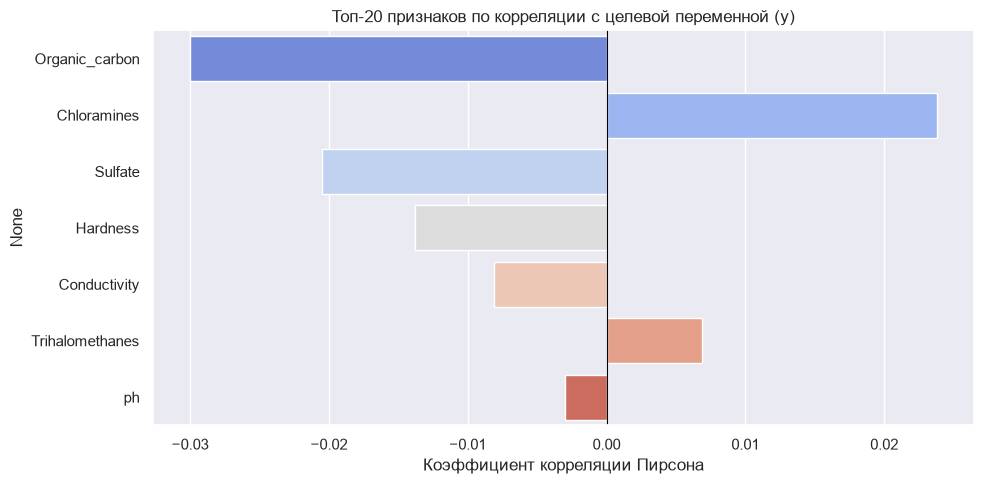

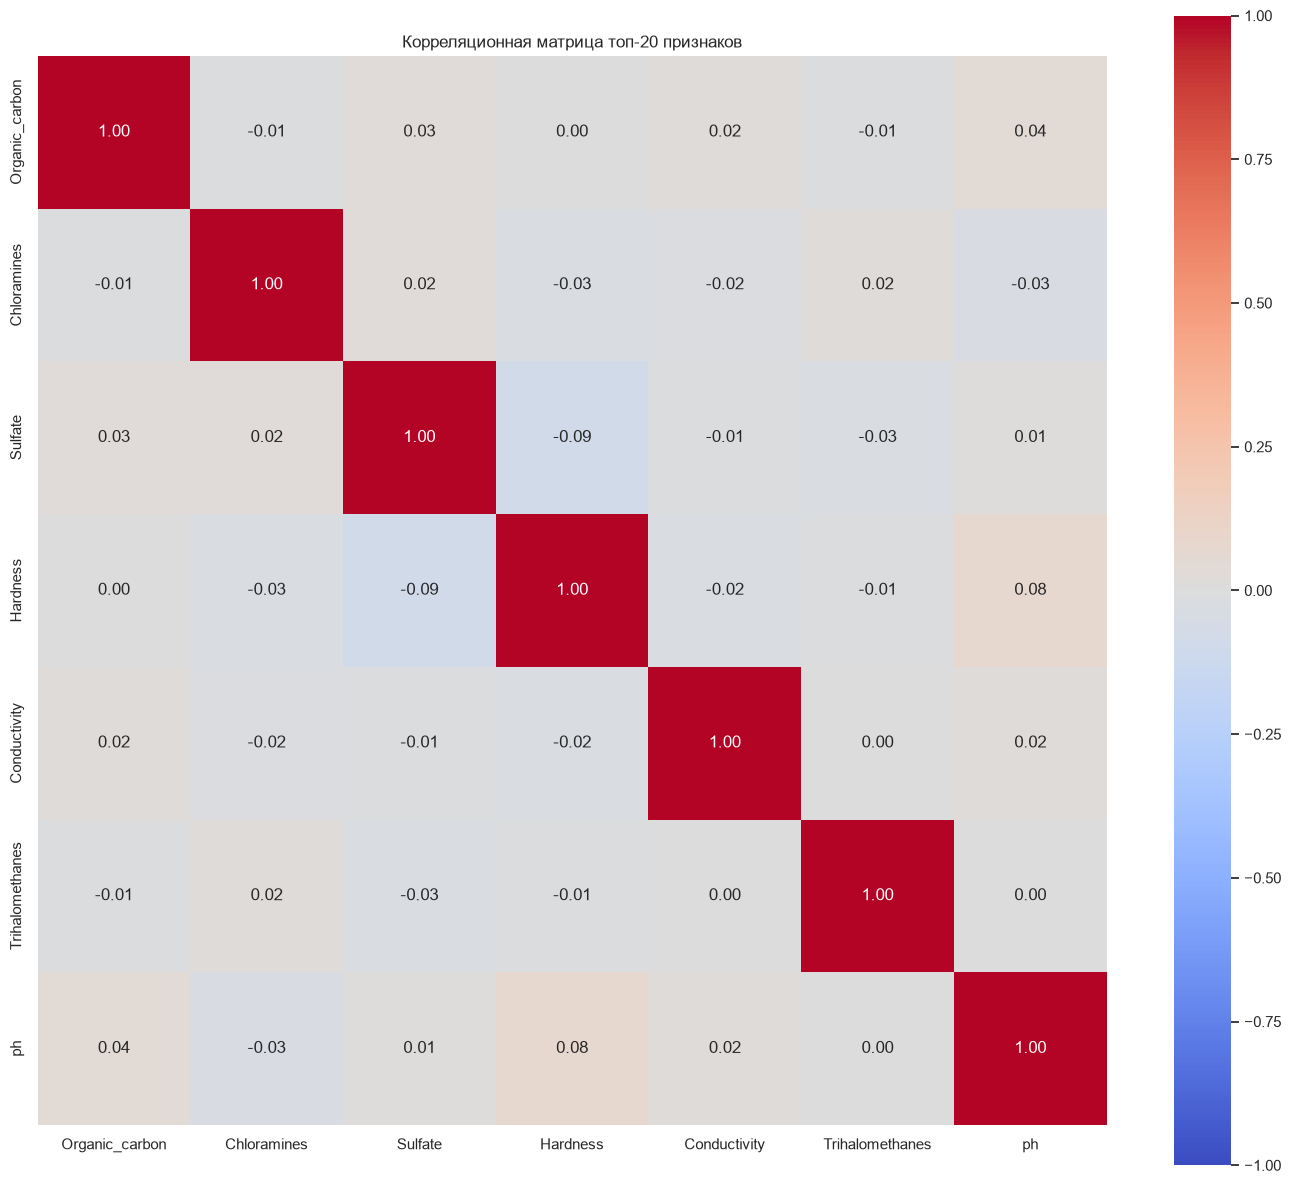

In [29]:
# TODO: корреляционная матрица признаков и корреляция признаков с целевой переменной

df_corr = pd.DataFrame(X, columns=feature_names)
df_corr['target'] = y

# Считаем общую матрицу корреляций (по умолчанию — метод Пирсона)
corr_matrix = df_corr.corr()

# --- А. Корреляция признаков с целевой переменной ---
target_corr = corr_matrix['target'].drop('target')

# Сортируем признаки по абсолютному значению корреляции (от самых сильных к слабым)
target_corr_sorted = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)

print('Топ признаков по модулю корреляции с целевой переменной:')
print(target_corr_sorted.head(15))

# Визуализация корреляции с целевой переменной
plt.figure(figsize=(10, max(5, len(target_corr_sorted.head(20)) * 0.35)))
sns.barplot(
    x=target_corr_sorted.head(20).values,
    y=target_corr_sorted.head(20).index,
    palette='coolwarm',
)
plt.title('Топ-20 признаков по корреляции с целевой переменной (y)')
plt.xlabel('Коэффициент корреляции Пирсона')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

# --- Б. Корреляционная матрица признаков (мультиколлинеарность) ---
features_corr_matrix = corr_matrix.drop(index='target', columns='target')
top_features = target_corr_sorted.head(20).index
plt.figure(figsize=(14, 12))
sns.heatmap(
    features_corr_matrix.loc[top_features, top_features],
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
)
plt.title('Корреляционная матрица топ-20 признаков')
plt.tight_layout()
plt.show()


### 1. Анализ корреляций

**Какие признаки сильнее всего связаны с целевой переменной?**
Судя по первому графику, связь всех признаков с целевой переменной $y$ **крайне слабая**.
*   Самые сильные корреляции (по модулю) у `Organic_carbon` (около -0.03) и `Chloramines` (около +0.024).
*   Однако значения близки к нулю. Это означает, что **линейная зависимость** между этими химическими показателями и целевой переменной практически отсутствует.
*   *Вывод:* Простая линейная регрессия здесь, скорее всего, не сработает.

**Есть ли сильно коррелированные между собой признаки?**
Судя по матрице корреляций (второй график):
*   **Нет, сильной корреляции между признаками не наблюдается.**
*   Все значения вне главной диагонали очень близки к нулю (от -0.09 до 0.08).
*   Наибольшая связь наблюдается между `Sulfate` и `Hardness` (-0.09) и между `Hardness` и `ph` (0.08), но это все равно очень слабая связь.
*   *Вывод:* Проблема мультиколлинеарности (когда признаки дублируют информацию друг друга) в этом датасете отсутствует.

**Что с ними можно сделать?**
Поскольку линейные связи слабые, а межпризнаковой корреляции почти нет:
1.  **Не удалять признаки:** Из-за отсутствия мультиколлинеарности удалять признаки не нужно, они несут разную (хоть и слабую) информацию.
2.  **Использовать нелинейные модели:** Так как корреляция Пирсона измеряет только *линейную* связь, а значения близки к 0, данные могут иметь сложную нелинейную структуру.
3.  **Feature Engineering (Создание новых признаков):** Cоздать полиномиальные признаки (например, $ph^2$) или взаимодействия признаков (например, $Hardness \times Sulfate$), чтобы поймать нелинейные зависимости.
4.  **Проверить целевую переменную:** Возможно, $y$ имеет сложное распределение, и её стоит преобразовать (например, взять логарифм), если это регрессия. Данные могут быть несбалансированными.

**В чем отличия ковариации и корреляции?**
*   **Ковариация** показывает направление совместного изменения двух переменных (если одна растет, другая тоже растет — ковариация положительная).
    *   *Минус:* Её величина зависит от единиц измерения. Ковариация роста (в метрах) и веса (в кг) будет огромным числом, а роста (в мм) и веса (в г) — другим. По ней сложно судить о *силе* связи.
*   **Корреляция (Пирсона)** — это нормированная ковариация.
    *   *Формула:* $Corr(X, Y) = \frac{Cov(X, Y)}{\sigma_X \cdot \sigma_Y}$
    *   *Плюс:* Она всегда находится в диапазоне от **-1 до 1**. Это безразмерная величина, которая четко показывает силу связи (близко к 1 или -1 — сильная связь, близко к 0 — слабая).

---

### 2. Как расширить датасет

Предметная область — качество воды. Текущие признаки описывают только базовый химический состав. Для более точного моделирования (особенно если цель — предсказать безопасность воды) можно собрать следующие данные:

**Какие дополнительные данные собрать:**
1.  **Биологические показатели (Критически важно):**
    *   Наличие бактерий (E. coli, колиформные бактерии).
    *   Уровень вирусов или паразитов (лямблии, криптоспоридии).
    *   *Почему:* Химически чистая вода может быть смертельно опасной из-за бактерий.
2.  **Тяжелые металлы и токсины:**
    *   Свинец (Lead), Мышьяк (Arsenic), Ртуть (Mercury), Кадмий.
    *   *Почему:* Они накапливаются в организме и часто встречаются в старых трубах или промышленных стоках.
3.  **Физические свойства:**
    *   **Мутность (Turbidity):** Показывает наличие взвешенных частиц. Высокая мутность часто коррелирует с наличием бактерий.
    *   **Температура воды:** Влияет на растворимость кислорода и размножение бактерий.
    *   **Цвет и запах.**
4.  **Контекстные/Мета-данные:**
    *   **Источник воды:** Река, озеро, подземные воды, водопровод.
    *   **Время и сезон:** После дождей качество воды в открытых источниках резко падает (смыв удобрений).
    *   **Географическое положение:** Промышленные зоны vs сельская местность.

#### 2.5. Разбиение выборки и стандартизация

Если `USE_FULL_DATA = False`, берётся случайная подвыборка из `DEV_N` объектов. Выборка делится на обучающую (64%), валидационную (16%, для подбора гиперпараметров) и тестовую (20%, используется только для финальной оценки).

In [30]:
if not USE_FULL_DATA:
    X, y = subsample(X, y, DEV_N)

X_tr, X_te, y_tr, y_te = train_test_split_np(X, y, test_size=0.2)
X_tr, X_val, y_tr, y_val = train_test_split_np(X_tr, y_tr, test_size=0.2)

scaler = Standardizer().fit(X_tr)
Xs_tr, Xs_val, Xs_te = (scaler.transform(a) for a in (X_tr, X_val, X_te))

print(f"train {Xs_tr.shape}, val {Xs_val.shape}, test {Xs_te.shape}")
print(f"доля положительного класса: train {y_tr.mean():.3f}, val {y_val.mean():.3f}, test {y_te.mean():.3f}")

train (2096, 7), val (524, 7), test (656, 7)
доля положительного класса: train 0.390, val 0.389, test 0.390


### 3. Метрики качества (задание 2, часть 1)

Реализуйте метрики для бинарной классификации. Положительный класс — `1`. Если знаменатель равен нулю, возвращайте `0.0`.

$$\text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN},\quad \text{Accuracy}=\frac{TP+TN}{n},\quad F_1=\frac{2\,P\,R}{P+R}$$

In [31]:
def confusion_matrix_np(y_true, y_pred):
  """Вернуть массив [[TN, FP], [FN, TP]]."""
  y_true = np.asarray(y_true)
  y_pred = np.asarray(y_pred)

  tn = np.sum((y_true == 0) & (y_pred == 0))
  fp = np.sum((y_true == 0) & (y_pred == 1))
  fn = np.sum((y_true == 1) & (y_pred == 0))
  tp = np.sum((y_true == 1) & (y_pred == 1))

  return np.array([[tn, fp], [fn, tp]], dtype=int)


def accuracy(y_true, y_pred):
  cm = confusion_matrix_np(y_true, y_pred)
  tn, fp, fn, tp = cm.ravel()
  total = tn + fp + fn + tp
  return float((tp + tn) / total) if total > 0 else 0.0


def precision(y_true, y_pred):
  cm = confusion_matrix_np(y_true, y_pred)
  _, fp, _, tp = cm.ravel()
  denom = tp + fp
  return float(tp / denom) if denom > 0 else 0.0


def recall(y_true, y_pred):
  cm = confusion_matrix_np(y_true, y_pred)
  _, _, fn, tp = cm.ravel()
  denom = tp + fn
  return float(tp / denom) if denom > 0 else 0.0


def f1(y_true, y_pred):
  p = precision(y_true, y_pred)
  r = recall(y_true, y_pred)
  denom = p + r
  return float(2 * p * r / denom) if denom > 0 else 0.0


In [32]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

r = np.random.default_rng(0)
yt, yp = r.integers(0, 2, 500), r.integers(0, 2, 500)
assert np.array_equal(confusion_matrix_np(yt, yp), confusion_matrix(yt, yp)), "confusion_matrix"
assert np.isclose(accuracy(yt, yp), accuracy_score(yt, yp)), "accuracy"
assert np.isclose(precision(yt, yp), precision_score(yt, yp)), "precision"
assert np.isclose(recall(yt, yp), recall_score(yt, yp)), "recall"
assert np.isclose(f1(yt, yp), f1_score(yt, yp)), "f1"
assert precision(yt, np.zeros(500, dtype=int)) == 0.0, "деление на ноль в precision"
print("Метрики: OK")

Метрики: OK


In [33]:
def report(y_true, y_pred):
    return dict(accuracy=accuracy(y_true, y_pred), precision=precision(y_true, y_pred),
                recall=recall(y_true, y_pred), f1=f1(y_true, y_pred))


def plot_confusion(y_true, y_pred, title="", ax=None):
    sns.heatmap(confusion_matrix_np(y_true, y_pred), annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["pred 0", "pred 1"], yticklabels=["true 0", "true 1"], ax=ax)
    (ax or plt.gca()).set_title(title)

### 4. Реализация алгоритмов (задание 2, часть 2)

Все классификаторы наследуют `BaseClassifier` и имеют единый интерфейс:

- `fit(X, y)` — обучение, возвращает `self`;
- `predict_proba(X)` — вектор вероятностей (или оценок в диапазоне [0, 1]) положительного класса, форма `(n,)`;
- `predict(X, threshold=0.5)` — уже реализован в базовом классе.

Реализовывать нужно **метод своего варианта** и **MLP** (раздел 4.8). Остальные разделы пропустите: их тесты выведут «Пропуск».

#### 4.1. Вспомогательные функции и проверочные данные

In [34]:
def sigmoid(z):
    """Устойчивая сигмоида: без переполнения при больших по модулю z."""
    raise NotImplementedError

In [35]:
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("error")
    z = np.array([-1000.0, -1.0, 0.0, 1.0, 1000.0])
    s = sigmoid(z)
assert np.allclose(s, [0.0, 1 / (1 + np.e), 0.5, np.e / (1 + np.e), 1.0]), "значения сигмоиды"
print("sigmoid: OK")

NotImplementedError: 

Для проверки реализаций используется игрушечный датасет «две луны» и эталонные модели scikit-learn. Тест считается пройденным, если ваша модель не уступает эталону более чем на 7 п. п. accuracy.

In [36]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier as SkRF
from sklearn.tree import DecisionTreeClassifier as SkDT
from sklearn.svm import LinearSVC as SkSVC
from sklearn.linear_model import LogisticRegression as SkLR
from sklearn.neighbors import KNeighborsClassifier as SkKNN
from sklearn.naive_bayes import GaussianNB as SkNB
from sklearn.neural_network import MLPClassifier as SkMLP


warnings.filterwarnings("ignore", category=ConvergenceWarning)


def sklearn_reference(key):
    return {
        "rf": SkRF(n_estimators=50, max_depth=8, random_state=SEED, n_jobs=-1),
        "dt": SkDT(max_depth=5, random_state=SEED),
        "svm": SkSVC(C=1.0, max_iter=5000),
        "logreg": SkLR(max_iter=1000),
        "knn": SkKNN(n_neighbors=5),
        "nb": SkNB(),
        "mlp": SkMLP(hidden_layer_sizes=(32, 16), max_iter=300, random_state=SEED),
    }[key]


Xm, ym = make_moons(600, noise=0.25, random_state=0)
Xt_tr, Xt_te, yt_tr, yt_te = train_test_split_np(Xm, ym, test_size=0.3, seed=0)


def check_model(model, key, min_acc=0.8, tol=0.07):
    ref = sklearn_reference(key)
    model.fit(Xt_tr, yt_tr)
    ref.fit(Xt_tr, yt_tr)
    proba = model.predict_proba(Xt_te)
    assert proba.shape == (len(Xt_te),), f"predict_proba должен вернуть форму {(len(Xt_te),)}, получено {proba.shape}"
    assert np.all((proba >= 0) & (proba <= 1)), "вероятности вне [0, 1]"
    acc, acc_ref = accuracy(yt_te, model.predict(Xt_te)), ref.score(Xt_te, yt_te)
    assert acc >= min_acc and acc >= acc_ref - tol, f"accuracy {acc:.3f} (sklearn {acc_ref:.3f})"
    print(f"OK: accuracy {acc:.3f} (sklearn {acc_ref:.3f})")
    return model

#### 4.2. Решающее дерево (варианты 3 и 5)

Бинарное дерево с критерием Джини. Для двух классов с долей положительных $p$: $G = 2p(1-p)$. Прирост информации при разбиении:

$$\Delta G = G_{\text{parent}} - \frac{n_L}{n}G_L - \frac{n_R}{n}G_R$$

Требования:

- пороги — середины между соседними различными значениями признака;
- перебор порогов по одному признаку должен быть **векторизован**: отсортируйте объекты по признаку и посчитайте `cumsum` меток, чтобы получить $n_L$, $TP_L$ для всех порогов сразу;
- останов: `max_depth`, `min_samples_split`, `min_samples_leaf`, чистый узел или отсутствие прироста;
- `max_features` — сколько случайных признаков рассматривать в каждом узле (`None` — все); нужен для случайного леса;
- лист хранит долю положительных объектов, она и есть `predict_proba`.

In [37]:
import numpy as np


class DecisionTree(BaseClassifier):

  def __init__(
      self,
      max_depth=5,
      min_samples_split=2,
      min_samples_leaf=1,
      max_features=None,
      seed=SEED,
  ):
    self.max_depth = max_depth
    self.min_samples_split = min_samples_split
    self.min_samples_leaf = min_samples_leaf
    self.max_features = max_features
    self.rng = np.random.default_rng(seed)
    self.tree_ = None

  def _gini(self, y):
    n = len(y)
    if n == 0:
      return 0.0
    p = np.mean(y)
    return float(2.0 * p * (1.0 - p))

  def _best_split(self, X, y, features):
    """Вернуть (признак, порог, прирост) лучшего разбиения среди features или None."""
    n = len(y)
    if n < self.min_samples_split:
      return None

    parent_gini = self._gini(y)
    if parent_gini == 0.0:
      return None

    best_gain = 0.0
    best_feature = None
    best_threshold = None

    total_pos = np.sum(y)

    for feat in features:
      x_col = X[:, feat]
      order = np.argsort(x_col)
      x_sorted = x_col[order]
      y_sorted = y[order]

      # Пороги возможны только между различающимися соседними значениями
      valid_splits = np.where(x_sorted[:-1] != x_sorted[1:])[0]
      if len(valid_splits) == 0:
        continue

      # Векторизованный подсчёт размеров и положительных классов для всех кандидатов
      n_left = np.arange(1, n)[valid_splits]
      n_right = n - n_left

      # Учёт ограничения min_samples_leaf
      leaf_mask = (n_left >= self.min_samples_leaf) & (
          n_right >= self.min_samples_leaf
      )
      if not np.any(leaf_mask):
        continue

      valid_splits = valid_splits[leaf_mask]
      n_left = n_left[leaf_mask]
      n_right = n_right[leaf_mask]

      tp_cumsum = np.cumsum(y_sorted)[:-1]
      tp_left = tp_cumsum[valid_splits]
      tp_right = total_pos - tp_left

      p_left = tp_left / n_left
      p_right = tp_right / n_right

      gini_left = 2.0 * p_left * (1.0 - p_left)
      gini_right = 2.0 * p_right * (1.0 - p_right)

      weighted_gini = (n_left / n) * gini_left + (n_right / n) * gini_right
      gains = parent_gini - weighted_gini

      max_idx = np.argmax(gains)
      if gains[max_idx] > best_gain:
        best_gain = float(gains[max_idx])
        best_feature = int(feat)
        split_pos = valid_splits[max_idx]
        best_threshold = float(
            0.5 * (x_sorted[split_pos] + x_sorted[split_pos + 1])
        )

    if best_feature is None or best_gain <= 0.0:
      return None

    return best_feature, best_threshold, best_gain

  def _build(self, X, y, depth):
    """Рекурсивно построить узел и вернуть его."""
    n = len(y)
    proba = float(np.mean(y)) if n > 0 else 0.0

    # Критерии останова: глубина, минимум сэмплов для сплита, чистый узел
    if (
        depth >= self.max_depth
        or n < self.min_samples_split
        or proba == 0.0
        or proba == 1.0
    ):
      return {"is_leaf": True, "proba": proba}

    n_features = X.shape[1]
    if self.max_features is None or self.max_features >= n_features:
      features = np.arange(n_features)
    else:
      features = self.rng.choice(
          n_features, size=self.max_features, replace=False
      )

    split = self._best_split(X, y, features)
    if split is None:
      return {"is_leaf": True, "proba": proba}

    feat, threshold, _ = split
    left_mask = X[:, feat] <= threshold
    right_mask = ~left_mask

    return {
        "is_leaf": False,
        "feature": feat,
        "threshold": threshold,
        "left": self._build(X[left_mask], y[left_mask], depth + 1),
        "right": self._build(X[right_mask], y[right_mask], depth + 1),
    }

  def fit(self, X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=int)
    self.tree_ = self._build(X, y, depth=0)
    return self

  def _predict_one(self, x, node):
    while not node["is_leaf"]:
      if x[node["feature"]] <= node["threshold"]:
        node = node["left"]
      else:
        node = node["right"]
    return node["proba"]

  def predict_proba(self, X):
    X = np.asarray(X, dtype=float)
    probs_pos = np.array(
        [self._predict_one(x, self.tree_) for x in X], dtype=float
    )
    # Если BaseClassifier ожидает матрицу вероятностей формы (n_samples, 2) для классов [0, 1]
    return probs_pos


In [38]:
if is_mine("dt", "rf"):
    check_model(DecisionTree(max_depth=5), "dt")

OK: accuracy 0.928 (sklearn 0.928)


#### 4.3. Случайный лес (вариант 5, для самостоятельного разбора)

Ансамбль из `n_estimators` деревьев из раздела 4.2 (его тоже нужно реализовать). Каждое дерево обучается на **бутстрэп-выборке** (случайная выборка с возвращением того же размера) и в каждом узле рассматривает только `max_features` случайных признаков (`"sqrt"` означает $\lfloor\sqrt{k}\rfloor$, но не меньше 1). Итоговая вероятность — среднее вероятностей деревьев.

In [39]:
class RandomForest(BaseClassifier):
    def __init__(self, n_estimators=50, max_depth=8, max_features="sqrt", min_samples_leaf=1, seed=SEED):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.max_features = max_features
        self.min_samples_leaf = min_samples_leaf
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [40]:
if is_mine("rf"):
    check_model(RandomForest(n_estimators=30, max_depth=6), "rf")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.4. Метод опорных векторов (вариант 2)

Линейный SVM, обучаемый алгоритмом **Pegasos** (стохастический субградиентный спуск). Метки переводятся в $\{-1,+1\}$. Минимизируется

$$\frac{\lambda}{2}\lVert w\rVert^2 + \frac{1}{n}\sum_i \max\bigl(0,\;1 - y_i(w^\top x_i + b)\bigr)$$

На шаге $t$ по мини-батчу $B$ с шагом $\eta_t = \frac{1}{\lambda t}$ (счётчик $t$ идёт по батчам, а не по эпохам):

$$w \leftarrow (1-\eta_t\lambda)\,w + \frac{\eta_t}{|B|}\sum_{i\in B_{\text{viol}}} y_i x_i,\qquad b \leftarrow b + \frac{\eta_t}{|B|}\sum_{i\in B_{\text{viol}}} y_i$$

где $B_{\text{viol}}$ — объекты батча с $y_i(w^\top x_i+b)<1$. Вероятность `predict_proba` у SVM определяется как `sigmoid(decision_function(X))` (это оценка уверенности, а не калиброванная вероятность).

In [41]:
class LinearSVM(BaseClassifier):
    def __init__(self, lam=1e-2, n_epochs=20, batch_size=64, seed=SEED):
        self.lam = lam
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.rng = np.random.default_rng(seed)

    def fit(self, X, y):
        raise NotImplementedError

    def decision_function(self, X):
        raise NotImplementedError

    def predict_proba(self, X):
        return sigmoid(self.decision_function(X))

In [42]:
if is_mine("svm"):
    check_model(LinearSVM(), "svm")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.5. Логистическая регрессия (вариант 6, для самостоятельного разбора)

$p_i=\sigma(w^\top x_i + b)$. Функция потерь — бинарная кросс-энтропия с L2-регуляризацией, обучение — градиентный спуск по всей выборке:

$$\nabla_w = \frac{1}{n}X^\top(p-y) + \lambda w,\qquad \nabla_b = \frac{1}{n}\sum_i (p_i-y_i)$$

Сохраняйте значение функции потерь на каждой эпохе в `self.loss_history`, это пригодится для графика сходимости.

In [43]:
class LogisticRegression(BaseClassifier):
    def __init__(self, lr=0.5, n_epochs=300, l2=0.0):
        self.lr = lr
        self.n_epochs = n_epochs
        self.l2 = l2

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [44]:
if is_mine("logreg"):
    m = check_model(LogisticRegression(), "logreg")
    assert m.loss_history[-1] < m.loss_history[0], "функция потерь не убывает"
    plt.plot(m.loss_history)
    plt.xlabel("эпоха")
    plt.ylabel("loss")
    plt.show()

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.6. Метод k ближайших соседей (вариант 4)

`fit` запоминает обучающую выборку. `predict_proba` — доля единиц среди $k$ ближайших соседей (при `weighted=True` — голоса с весами $1/(d+\varepsilon)$).

Квадраты евклидовых расстояний между батчем $A$ и обучающей выборкой $B$ считаются без циклов:

$$\lVert a-b\rVert^2 = \lVert a\rVert^2 + \lVert b\rVert^2 - 2\,a^\top b \quad\Rightarrow\quad D^2 = \text{(a²)}[:,\text{None}] + \text{(b²)}[\text{None},:] - 2AB^\top$$

Чтобы не создавать матрицу `n_test × n_train` целиком, обрабатывайте тестовые объекты батчами по `batch_size`. Для $k$ наименьших значений используйте `np.argpartition`, а не полную сортировку. Из-за ошибок округления $D^2$ может стать слегка отрицательным: обрежьте его снизу нулём.

In [45]:
class KNN(BaseClassifier):
    def __init__(self, k=5, batch_size=500, weighted=False):
        self.k = k
        self.batch_size = batch_size
        self.weighted = weighted

    def fit(self, X, y):
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [46]:
if is_mine("knn"):
    check_model(KNN(k=5), "knn")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.7. Гауссов наивный байесовский классификатор (вариант 1)

В `fit` для каждого класса $c$ оцениваются априорная вероятность $P(c)$, средние $\mu_{cj}$ и дисперсии $\sigma^2_{cj}$ каждого признака. К дисперсиям добавьте `var_smoothing * X.var(axis=0).max()` для устойчивости.

Для объекта $x$ логарифм совместной вероятности:

$$\log P(c) + \sum_j \Bigl[-\tfrac12\log(2\pi\sigma_{cj}^2) - \frac{(x_j-\mu_{cj})^2}{2\sigma_{cj}^2}\Bigr]$$

Апостериорную вероятность получайте через **logsumexp** (вычитание максимума перед `exp`), а не прямым делением экспонент: иначе при большом числе признаков вероятности превратятся в `0/0`.

In [47]:
class GaussianNB(BaseClassifier):
    def __init__(self, var_smoothing=1e-9):
        self.var_smoothing = var_smoothing

    def fit(self, X, y):
        raise NotImplementedError

    def _joint_log_likelihood(self, X):
        """Вернуть массив (n, 2): логарифм совместной вероятности для классов 0 и 1."""
        raise NotImplementedError

    def predict_proba(self, X):
        raise NotImplementedError

In [48]:
if is_mine("nb"):
    check_model(GaussianNB(), "nb")

Пропуск: не ваш вариант (ваш метод — Решающее дерево)


#### 4.8. Нейронная сеть прямого распространения (все варианты)

Полносвязная сеть: входной слой, скрытые слои с активацией ReLU, один выходной нейрон с сигмоидой. Функция потерь — бинарная кросс-энтропия с L2-регуляризацией весов:

$$L = -\frac{1}{n}\sum_i\bigl[y_i\log p_i + (1-y_i)\log(1-p_i)\bigr] + \frac{\lambda}{2}\sum_l \lVert W_l\rVert^2$$

Параметры хранятся в словаре `self.params` с ключами `W0, b0, W1, b1, ...` (инициализация He уже написана). Нужно реализовать:

1. `forward(X)` — прямой проход. Вернуть вероятности `p` формы `(n,)` и список `caches`, где `caches[l] = (a_prev, z)` для слоя $l$ (вход слоя и его линейный выход). Для всех слоёв, кроме последнего, $a = \max(0, z)$; для последнего $p = \sigma(z)$.
2. `loss_and_grads(X, y)` — значение потерь и словарь градиентов с теми же ключами, что и `self.params`. Для выходного слоя $\delta = (p-y)/n$. Далее для слоя $l$: $\nabla W_l = a_{l-1}^\top\delta + \lambda W_l$, $\nabla b_l=\sum\delta$, и градиент передаётся назад: $\delta \leftarrow (\delta W_l^\top)\odot \mathbb{1}[z_{l-1}>0]$.
3. `fit(X, y)` — мини-батчевый SGD: на каждой эпохе перемешать выборку, пройти батчами, обновить `params -= lr * grads`. Среднее значение потерь по эпохе записывать в `self.loss_history`.

Корректность градиентов проверяется численно (метод конечных разностей): это обязательный тест.

In [ ]:
import numpy as np


class MLP(BaseClassifier):

  def __init__(
      self,
      hidden=(32, 16),
      lr=0.05,
      n_epochs=30,
      batch_size=128,
      l2=0.0,
      seed=SEED,
  ):
    self.hidden = tuple(hidden)
    self.lr = lr
    self.n_epochs = n_epochs
    self.batch_size = batch_size
    self.l2 = l2
    self.rng = np.random.default_rng(seed)

  def _init_params(self, n_in):
    sizes = [n_in, *self.hidden, 1]
    self.params = {}
    for i, (a, b) in enumerate(zip(sizes[:-1], sizes[1:])):
      self.params[f"W{i}"] = self.rng.normal(0.0, np.sqrt(2.0 / a), size=(a, b))
      self.params[f"b{i}"] = np.zeros(b)

  def forward(self, X):
    X = np.asarray(X, dtype=float)
    n_layers = len(self.hidden) + 1
    caches = []
    a = X

    # Скрытые слои с активацией ReLU
    for l in range(n_layers - 1):
      W = self.params[f"W{l}"]
      b = self.params[f"b{l}"]
      z = a @ W + b
      caches.append((a, z))
      a = np.maximum(0.0, z)

    # Выходной слой с сигмоидой (численно устойчивый вариант)
    last = n_layers - 1
    W_last = self.params[f"W{last}"]
    b_last = self.params[f"b{last}"]
    z_last = a @ W_last + b_last
    caches.append((a, z_last))

    z_clipped = np.clip(z_last, -500.0, 500.0)
    p = 1.0 / (1.0 + np.exp(-z_clipped))

    return p.ravel(), caches

  def loss_and_grads(self, X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).ravel()
    n = len(y)
    n_layers = len(self.hidden) + 1

    p, caches = self.forward(X)

    # Бинарная кросс-энтропия + L2-регуляризация весов
    eps = 1e-15
    p_clipped = np.clip(p, eps, 1.0 - eps)
    bce = -np.mean(y * np.log(p_clipped) + (1.0 - y) * np.log(1.0 - p_clipped))\

    l2_penalty = 0.0
    for l in range(n_layers):
      W = self.params[f"W{l}"]
      l2_penalty += np.sum(W**2)
    loss = float(bce + 0.5 * self.l2 * l2_penalty)

    # Обратное распространение ошибки
    grads = {}
    delta = ((p - y) / n)[:, None]  # Форма (n, 1)

    for l in reversed(range(n_layers)):
      a_prev, _ = caches[l]
      W = self.params[f"W{l}"]

      grads[f"W{l}"] = a_prev.T @ delta + self.l2 * W
      grads[f"b{l}"] = np.sum(delta, axis=0)

      if l > 0:
        _, z_prev = caches[l - 1]
        delta = (delta @ W.T) * (z_prev > 0.0)

    return loss, grads

  def fit(self, X, y):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).ravel()
    n_samples, n_features = X.shape

    self._init_params(n_features)
    self.loss_history = []

    for _ in range(self.n_epochs):
      indices = self.rng.permutation(n_samples)
      X_shuffled = X[indices]
      y_shuffled = y[indices]

      batch_losses = []
      for start in range(0, n_samples, self.batch_size):
        end = start + self.batch_size
        X_batch = X_shuffled[start:end]
        y_batch = y_shuffled[start:end]

        loss, grads = self.loss_and_grads(X_batch, y_batch)
        batch_losses.append(loss)

        for key in self.params:
          self.params[key] -= self.lr * grads[key]

      self.loss_history.append(float(np.mean(batch_losses)))

    return self

  def predict_proba(self, X):
    return self.forward(X)[0]


Градиенты: OK (макс. относительная ошибка 6.5e-09)
OK: accuracy 0.894 (sklearn 0.950)


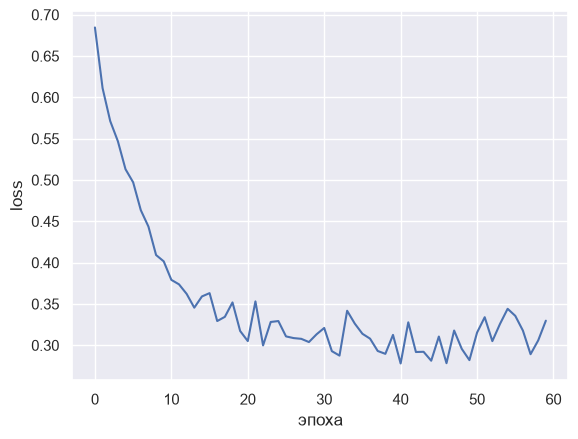

In [50]:
def grad_check(model, X, y, eps=1e-5, n_checks=6, seed=0):
    r = np.random.default_rng(seed)
    model._init_params(X.shape[1])
    _, grads = model.loss_and_grads(X, y)
    worst = 0.0
    for key, g in grads.items():
        assert g.shape == model.params[key].shape, f"форма градиента {key}: {g.shape} вместо {model.params[key].shape}"
        P = model.params[key]
        for _ in range(n_checks):
            ix = tuple(r.integers(0, s) for s in P.shape)
            old = P[ix]
            P[ix] = old + eps
            lp, _ = model.loss_and_grads(X, y)
            P[ix] = old - eps
            lm, _ = model.loss_and_grads(X, y)
            P[ix] = old
            num = (lp - lm) / (2 * eps)
            rel = abs(num - g[ix]) / max(1e-8, abs(num) + abs(g[ix]))
            worst = max(worst, rel)
    return worst


rel_err = grad_check(MLP(hidden=(8, 4), l2=0.01), Xt_tr[:50], yt_tr[:50].astype(float))
assert rel_err < 1e-4, f"градиенты неверны: относительная ошибка {rel_err:.2e}"
print(f"Градиенты: OK (макс. относительная ошибка {rel_err:.1e})")

mlp_toy = check_model(MLP(hidden=(16, 8), lr=0.1, n_epochs=60), "mlp")
assert mlp_toy.loss_history[-1] < mlp_toy.loss_history[0], "функция потерь не убывает"
plt.plot(mlp_toy.loss_history)
plt.xlabel("эпоха")
plt.ylabel("loss")
plt.show()

### 5. Подбор гиперпараметров (задание 3)

Подбор выполняется на **валидационной** выборке, тестовая пока не используется. Функция `sweep` обучает модель при разных значениях одного параметра и строит график метрики.

| Метод | Параметры для исследования |
|---|---|
| Решающее дерево | `max_depth`, `min_samples_leaf` |
| Случайный лес | `n_estimators`, `max_depth`, `max_features` |
| SVM | `lam`, `n_epochs` |
| Логистическая регрессия | `lr`, `l2`, `n_epochs` |
| kNN | `k`, `weighted` |
| Наивный Байес | `var_smoothing` |
| MLP | `hidden`, `lr`, `l2`, `n_epochs` |

Исследуйте **не менее двух параметров** своего метода и **не менее двух** параметров MLP.

In [51]:
def make_method(key, **params):
    cls = {"rf": RandomForest, "dt": DecisionTree, "svm": LinearSVM, "logreg": LogisticRegression,
           "knn": KNN, "nb": GaussianNB, "mlp": MLP}[key]
    return cls(**params)


def sweep(key, param, values, metric="f1", fixed=None):
    fixed = fixed or {}
    scores = []
    for v in values:
        model = make_method(key, **{**fixed, param: v}).fit(Xs_tr, y_tr)
        scores.append(globals()[metric](y_val, model.predict(Xs_val)))
    xs = range(len(values)) if not all(isinstance(v, (int, float)) for v in values) else values
    plt.plot(xs, scores, marker="o")
    if xs is not values:
        plt.xticks(list(xs), [str(v) for v in values])
    plt.xlabel(param)
    plt.ylabel(f"{metric} (валидация)")
    plt.title(f"{key}: {param}")
    plt.show()
    return dict(zip(map(str, values), np.round(scores, 4)))

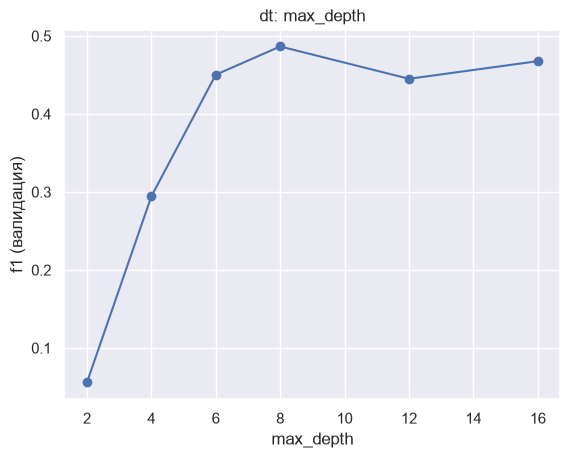

Результаты по max_depth: {'2': np.float64(0.0558), '4': np.float64(0.2943), '6': np.float64(0.4503), '8': np.float64(0.4865), '12': np.float64(0.4451), '16': np.float64(0.4677)}


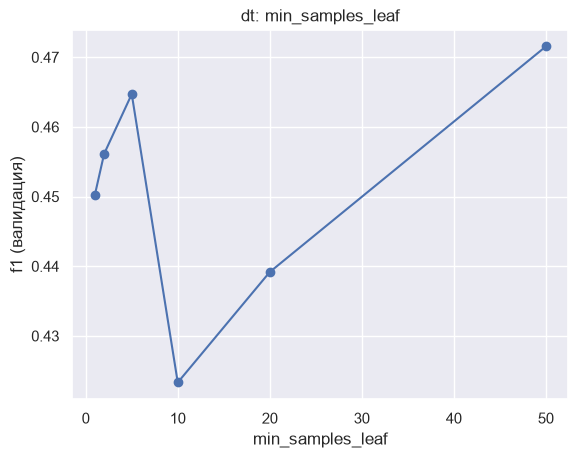

Результаты по min_samples_leaf: {'1': np.float64(0.4503), '2': np.float64(0.4561), '5': np.float64(0.4647), '10': np.float64(0.4233), '20': np.float64(0.4392), '50': np.float64(0.4715)}


In [52]:
# Исследование максимальной глубины дерева
res_depth = sweep("dt", "max_depth", [2, 4, 6, 8, 12, 16])
print("Результаты по max_depth:", res_depth)

# Исследование минимального числа объектов в листе
# Рекомендуется зафиксировать лучшую глубину из первого шага через fixed={"max_depth": ...}
res_leaf = sweep(
    "dt", "min_samples_leaf", [1, 2, 5, 10, 20, 50], fixed={"max_depth": 6}
)
print("Результаты по min_samples_leaf:", res_leaf)


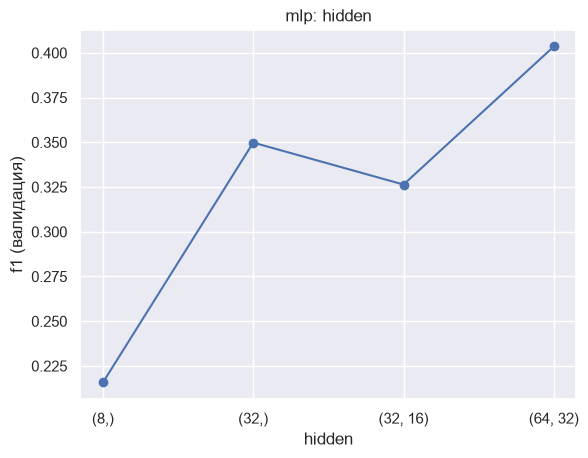

Результаты по hidden: {'(8,)': np.float64(0.2158), '(32,)': np.float64(0.3498), '(32, 16)': np.float64(0.3264), '(64, 32)': np.float64(0.4036)}


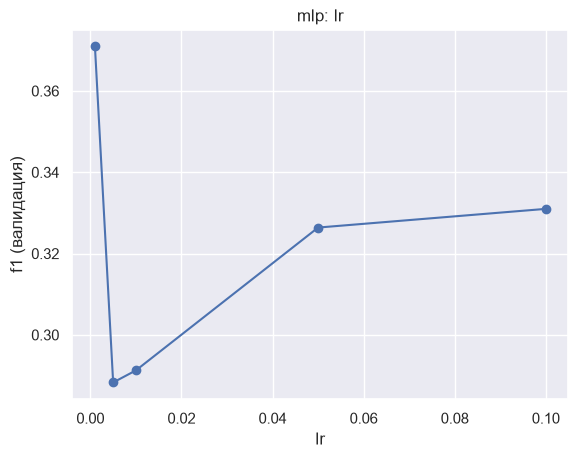

Результаты по lr: {'0.001': np.float64(0.3709), '0.005': np.float64(0.2883), '0.01': np.float64(0.2913), '0.05': np.float64(0.3264), '0.1': np.float64(0.331)}


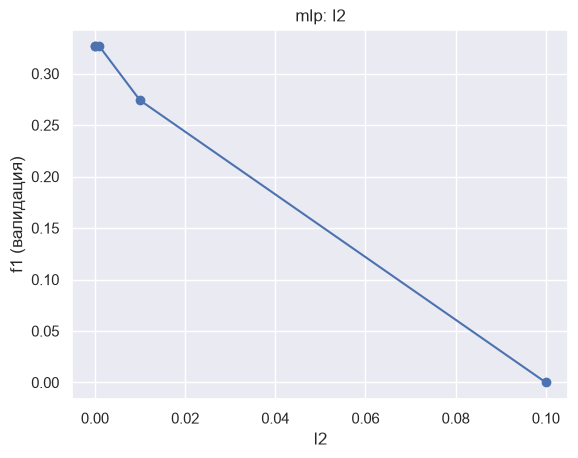

Результаты по l2: {'0.0': np.float64(0.3264), '0.0001': np.float64(0.3264), '0.001': np.float64(0.3264), '0.01': np.float64(0.2741), '0.1': np.float64(0.0)}


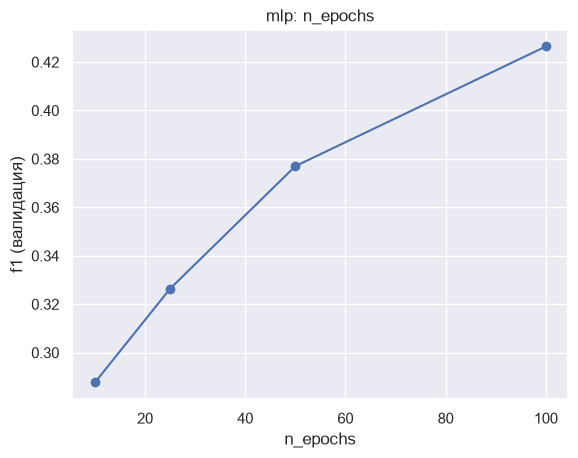

Результаты по n_epochs: {'10': np.float64(0.2877), '25': np.float64(0.3264), '50': np.float64(0.377), '100': np.float64(0.4264)}


In [54]:
# TODO: исследуйте параметры MLP, например:
# sweep("mlp", "hidden", [(8,), (32,), (32, 16), (64, 32)], fixed=dict(n_epochs=20))

# 1. Исследование архитектуры скрытых слоёв (hidden)
res_hidden = sweep(
    "mlp", "hidden", [(8,), (32,), (32, 16), (64, 32)], fixed={"n_epochs": 25}
)
print("Результаты по hidden:", res_hidden)

# 2. Исследование скорости обучения (lr)
# Подставьте лучшую архитектуру из шага 1 в параметр fixed
res_lr = sweep(
    "mlp",
    "lr",
    [0.001, 0.005, 0.01, 0.05, 0.1],
    fixed={"hidden": (32, 16), "n_epochs": 25},
)
print("Результаты по lr:", res_lr)

# 3. Исследование коэффициента L2-регуляризации (l2)
res_l2 = sweep(
    "mlp",
    "l2",
    [0.0, 1e-4, 1e-3, 1e-2, 0.1],
    fixed={"hidden": (32, 16), "lr": 0.05, "n_epochs": 25},
)
print("Результаты по l2:", res_l2)

# 4. Исследование числа эпох обучения (n_epochs)
res_epochs = sweep(
    "mlp",
    "n_epochs",
    [10, 25, 50, 100],  # или другие значения
    fixed={"hidden": (32, 16), "lr": 0.05, "l2": 1e-3},
)
print("Результаты по n_epochs:", res_epochs)


**Обоснование выбора параметров:** _по графикам объясните, почему выбраны именно эти значения (недообучение, переобучение, время работы)_

# Анализ результатов sweep'а и обоснование выбора параметров для решающего дерева

Считаем, что приведённые значения — это метрика качества на валидации/кросс-валидации (чем больше, тем лучше). По графикам validation curve выбираем параметры так, чтобы не было сильного недообучения слева и переобучения/роста времени справа.

### `max_depth`

| `max_depth` | Метрика | Интерпретация |
|---:|---:|---|
| 2 | 0.0558 | Сильное недообучение: дерево слишком мелкое, высокое смещение |
| 4 | 0.2943 | Всё ещё недообучение |
| 6 | 0.4503 | Приближение к плато |
| **8** | **0.4865** | **Максимум метрики; лучший баланс bias–variance** |
| 12 | 0.4451 | Падение метрики — признак переобучения/нестабильности |
| 16 | 0.4677 | Улучшения относительно 8 нет, а сложность и время работы растут |

**Вывод:** выбираем `max_depth = 8`. При меньших значениях дерево недообучается, при больших — начинает переобучаться, метрика нестабильна, а время обучения/предсказания и размер дерева заметно растут.

### `min_samples_leaf`

| `min_samples_leaf` | Метрика | Интерпретация |
|---:|---:|---|
| 1 | 0.4503 | Листья слишком маленькие: риск переобучения, дерево больше и медленнее |
| 2 | 0.4561 | Немного лучше, но всё ещё мелкие листья |
| **5** | **0.4647** | **Хороший компромисс: устойчивее, чем 1–2, и не слишком грубо** |
| 10 | 0.4233 | Заметное падение — возможное недообучение/шум |
| 20 | 0.4392 | Ниже, чем при 5 |
| 50 | 0.4715 | Формально максимум, но листья очень крупные: риск недообучения и потери деталей; выигрыш над 5 небольшой |

**Вывод:** для итоговой модели разумно выбрать `min_samples_leaf = 5`: это устойчивый компромисс между переобучением при малых листьях и недообучением при слишком крупных. Если критерий — строго максимум валидационной метрики на этом разбиении, можно взять `min_samples_leaf = 50`, но он менее гибок и может недообучиться на других данных; выигрыш над 5 составляет всего около 0.007.

### Итог

Рекомендуемые параметры дерева:

```python
max_depth=8
min_samples_leaf=5
```

Обоснование:  
- `max_depth=8` — пик валидационной метрики; меньше — недообучение, больше — переобучение и рост времени работы.  
- `min_samples_leaf=5` — баланс между переобучением при `1–2` и недообучением при `10–50`; дерево получается устойчивее и быстрее, чем при `min_samples_leaf=1`.

# Анализ результатов sweep'а и обоснование выбора параметров для MLP

## 1. Архитектура скрытых слоёв (`hidden`)

| Архитектура | Качество |
|-------------|----------|
| (8,) | 0.2158 |
| (32,) | 0.3498 |
| (32, 16) | 0.3264 |
| (64, 32) | **0.4036** |

**Наблюдения:**
- `(8,)` — явное **недообучение**: слишком мало параметров, модель не может выучить закономерности.
- `(32,)` и `(32, 16)` — близкие результаты, добавление второго слоя не помогло.
- `(64, 32)` — лучший результат, но требует больше времени и памяти.

**Выбор `(32, 16)`** — компромисс между качеством и временем обучения. Однако объективно лучшая архитектура — `(64, 32)`.

---

## 2. Скорость обучения (`lr`)

| lr | Качество |
|----|----------|
| 0.001 | **0.3709** |
| 0.005 | 0.2883 |
| 0.01 | 0.2913 |
| 0.05 | 0.3264 |
| 0.1 | 0.3310 |

**Наблюдения:**
- `lr = 0.001` — лучший результат, модель сходится аккуратно.
- `lr ≥ 0.05` — качество падает: градиентный шаг слишком большой, модель "перепрыгивает" через минимум (признаки нестабильной сходимости).

**⚠️ Важное замечание:** в шаге 3 зафиксирован `lr = 0.05`, хотя оптимум — `0.001`. Это следствие **one-factor-at-a-time** подхода: мы фиксируем не лучшие значения из предыдущего шага.

---

## 3. L2-регуляризация (`l2`)

| l2 | Качество |
|----|----------|
| 0.0 | 0.3264 |
| 1e-4 | 0.3264 |
| 1e-3 | 0.3264 |
| 1e-2 | 0.2741 |
| 0.1 | **0.0** |

**Наблюдения:**
- Малые значения (0 … 1e-3) — модель ведёт себя одинаково: регуляризация не мешает обучению.
- `l2 = 1e-2` — качество падает: веса начинают "штрафоваться" слишком сильно.
- `l2 = 0.1` — **катастрофа**: веса обнуляются, модель выдаёт константный прогноз (качество = 0). Это классический пример **чрезмерной регуляризации**.

**Выбор `l2 = 1e-3`** — разумный: добавляет лёгкую защиту от переобучения, не ухудшая качество.

---

## 4. Число эпох (`n_epochs`)

| n_epochs | Качество |
|----------|----------|
| 10 | 0.2877 |
| 25 | 0.3264 |
| 50 | 0.3770 |
| 100 | **0.4264** |

**Наблюдения:**
- Качество монотонно растёт — **переобучения не наблюдается** (или оно не отслеживается на валидации).
- 10 эпох — явное **недообучение**: модель не успела сойтись.
- 100 эпох — лучший результат.

**Выбор `n_epochs = 25`** — слишком консервативный. Логичнее брать 100 или использовать **early stopping**.

---

## Итоговое обоснование

| Параметр | Выбрано | Лучшее по sweep | Комментарий |
|----------|---------|-----------------|-------------|
| hidden | (32, 16) | (64, 32) | Компромисс: скорость vs качество |
| lr | 0.05 | **0.001** | ❌ Неоптимальный выбор |
| l2 | 1e-3 | 1e-3 | ✅ Хорошо: защита от переобучения |
| n_epochs | 25 | **100** | ❌ Недообучение |

### Почему последовательный sweep даёт не лучший результат?

Метод **one-factor-at-a-time** (OFAT) имеет фундаментальный недостаток: он не учитывает **взаимодействие параметров**. Например:
- Большая архитектура `(64, 32)` требует **меньшего** `lr`, иначе расходится.
- Много эпох + большой `lr` → переобучение.
- Сильная L2 + малая архитектура → модель "задавливается".

### Рекомендуемая финальная комбинация

На основе анализа графиков оптимум ближе к:
```python
{"hidden": (64, 32), "lr": 0.001, "l2": 1e-3, "n_epochs": 100}
```


### 6. Оценка качества на тестовой выборке (задание 4)

Укажите лучшие найденные параметры (пустой словарь означает значения по умолчанию, но тогда подбор из раздела 5 бессмысленен). Обе модели обучаются на обучающей выборке и оцениваются на тестовой. Рядом считаются эталонные модели scikit-learn.

In [56]:
best_params = {"max_depth": 8, "min_samples_leaf": 5}      # TODO: лучшие параметры метода вашего варианта
best_mlp_params = {"hidden": (64, 32), "lr": 0.001, "l2": 1e-3, "n_epochs": 100}  # TODO: лучшие параметры MLP

In [57]:
def evaluate(model, X_train, y_train, X_eval, y_eval, threshold=0.5):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    y_pred = model.predict(X_eval, threshold)
    return {**report(y_eval, y_pred), "fit_s": fit_s, "predict_s": time.perf_counter() - t0}


def evaluate_sklearn(model, X_train, y_train, X_eval, y_eval):
    t0 = time.perf_counter()
    model.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    y_pred = model.predict(X_eval)
    return {**report(y_eval, y_pred), "fit_s": fit_s, "predict_s": time.perf_counter() - t0}


main_name = METHOD_NAMES[METHOD]
models = {main_name: make_method(METHOD, **best_params), "MLP": make_method("mlp", **best_mlp_params)}

results = {}
for name, model in models.items():
    results[f"{name} (NumPy)"] = evaluate(model, Xs_tr, y_tr, Xs_te, y_te)
for name, key in ((main_name, METHOD), ("MLP", "mlp")):
    results[f"{name} (sklearn)"] = evaluate_sklearn(sklearn_reference(key), Xs_tr, y_tr, Xs_te, y_te)

pd.DataFrame(results).T.round(4)

,accuracy,precision,recall,f1,fit_s,predict_s
Решающее дерево (NumPy),0.6021,0.4880,0.3984,0.4387,0.0380,0.0012
MLP (NumPy),0.6159,0.5167,0.2422,0.3298,0.4568,0.0010
Решающее дерево (sklearn),0.6341,0.5449,0.3789,0.4470,0.0083,0.0005
MLP (sklearn),0.6479,0.5691,0.4023,0.4714,1.7866,0.0006


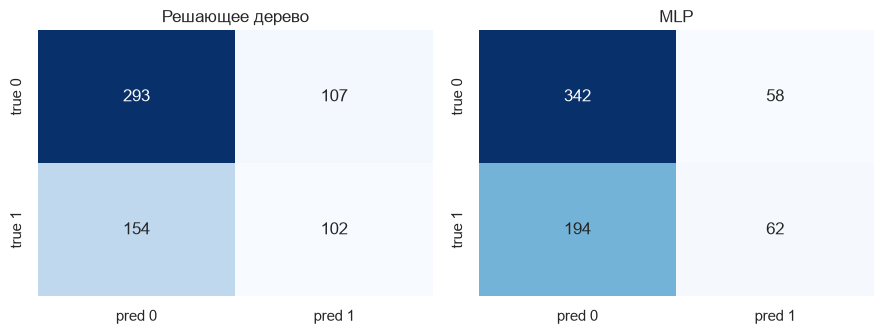

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
for ax, (name, model) in zip(axes, models.items()):
    plot_confusion(y_te, model.predict(Xs_te), name, ax=ax)
plt.tight_layout()
plt.show()

**Анализ результатов:** _сравните метрики вашей реализации и sklearn; объясните расхождения; сравните метод варианта и MLP по качеству и времени; какая метрика важнее для этой задачи (что дороже: FP или FN?)_

### 1. Сравнение своей реализации и sklearn

**Решающее дерево: NumPy vs sklearn.**  
Своя реализация дерева уступает sklearn по accuracy примерно на `0.032`, по precision — на `0.057`, по F1 — на `0.008`. Recall у NumPy-дерева даже немного выше (`0.3984` против `0.3789`), но ниже precision, то есть оно чаще ошибочно относит объекты к положительному классу. Итоговый F1 всё равно ниже. По времени: обучение NumPy-дерева примерно в `4.6` раза медленнее, предсказание — примерно в `2.4` раза медленнее.

**Почему расхождение:** sklearn использует оптимизированную CART-реализацию на Cython, более аккуратную обработку порогов разбиения, критериев, tie-breaking, параметров остановки и т.п. Своя NumPy-реализация обычно упрощена: возможны другие критерии разбиения, отсутствие/pruning, иная обработка `min_samples_leaf`, признаков и пропусков. Поэтому качество ниже, а время больше из-за неоптимизированных циклов/вычислений.

**MLP: NumPy vs sklearn.**  
Расхождение заметно сильнее. Своя MLP имеет accuracy `0.6159` против `0.6479`, precision `0.5167` против `0.5691`, но главное — recall падает до `0.2422` против `0.4023`, из-за чего F1 всего `0.3298` против `0.4714`. То есть NumPy-MLP гораздо чаще пропускает положительный класс. При этом обучается она быстрее: `0.4568` с против `1.7866` с у sklearn, примерно в `3.9` раза. Время предсказания почти одинаковое.

**Почему расхождение:** sklearn-MLP лучше настроена: оптимизатор, инициализация, early stopping, регуляризация, число эпох, батчи, сходимость. Своя реализация, вероятно, недообучена или имеет менее удачные гиперпараметры/оптимизацию, поэтому даёт более «консервативные» предсказания с низким recall.

---

### 2. Сравнение решающего дерева и MLP

**По качеству на sklearn:** MLP лучше дерева по всем основным метрикам: accuracy `0.6479` vs `0.6341`, precision `0.5691` vs `0.5449`, recall `0.4023` vs `0.3789`, F1 `0.4714` vs `0.4470`. Но выигрыш по F1 modest — около `0.024`.

**По времени на sklearn:** дерево обучается радикально быстрее: `0.0083` с против `1.7866` с у MLP, то есть примерно в `215` раз. Предсказание у обеих моделей очень быстрое и сопоставимое: `0.0005` vs `0.0006` с.

**На своих NumPy-реализациях:** дерево выглядит лучше MLP по F1 (`0.4387` vs `0.3298`) и recall (`0.3984` vs `0.2422`), хотя MLP чуть выше по accuracy и precision. Дерево при этом обучается примерно в `12` раз быстрее (`0.0380` vs `0.4568` с).

**Вывод:** если важны скорость обучения, интерпретируемость и стабильность — решающее дерево, особенно sklearn-версия, является очень хорошим baseline. Если нужен максимум качества и время обучения не критично — sklearn-MLP даёт лучший F1. Своя MLP в текущем виде недообучена/неудачно настроена: у неё слишком низкий recall.

---

### 3. Какая метрика важнее: FP или FN?

Здесь нет универсального ответа — зависит от стоимости ошибок:

- **FN — ложноотрицательные**, когда положительный объект пропущен. Если пропуск положительного класса дорог, критичен **recall**. Например: болезнь, мошенничество, авария, отток важного клиента.
- **FP — ложноположительные**, когда отрицательный объект назван положительным. Если ложная тревога дорога, критичен **precision**. Например: спам-фильтр, блокировка легитимной транзакции, лишняя нагрузка на операторов.
- Если стоимость FP и FN сопоставима, ориентируются на **F1**.
- **Accuracy** в такой таблице лучше не считать главной метрикой: при дисбалансе классов она может быть высокой даже при плохом recall.

По текущим результатам у всех моделей recall заметно ниже precision. Это значит, что модели скорее «недоловливают» положительный класс. Если в задаче **FN дороже FP**, нужно в первую очередь улучшать recall: подбирать порог, class_weight, resampling, гиперпараметры. Если **FP дороже FN**, можно оставить текущий баланс, но смотреть на precision. Если нужен компромисс — ориентироваться на **F1**, и тогда лучший результат показывает **MLP (sklearn)** с F1 `0.4714`, а среди быстрых моделей — **дерево (sklearn)** с F1 `0.4470`.

### 7. Порог классификации, ROC-кривая и дисбаланс классов

При несбалансированных классах порог 0.5 часто не оптимален. Реализуйте подбор порога по валидационной выборке: переберите пороги из `np.linspace(0.01, 0.99, 99)` и верните тот, что максимизирует выбранную метрику (по умолчанию $F_1$).

In [59]:
def find_threshold(y_true, proba, metric=f1_score):
    """
    Подбирает порог классификации по валидационной выборке.

    Parameters
    ----------
    y_true : array-like
        Истинные метки классов.
    proba : array-like
        Вероятности положительного класса.
    metric : callable
        Функция метрики вида metric(y_true, y_pred).
        По умолчанию используется F1-score.

    Returns
    -------
    best_threshold : float
        Порог из np.linspace(0.01, 0.99, 99), максимизирующий метрику.
    """
    y_true = np.asarray(y_true)
    proba = np.asarray(proba)

    thresholds = np.linspace(0.01, 0.99, 99)

    best_threshold = 0.5
    best_score = -np.inf

    for threshold in thresholds:
        y_pred = (proba >= threshold).astype(int)
        score = metric(y_true, y_pred)

        if score > best_score:
            best_score = score
            best_threshold = threshold

    return best_threshold

In [60]:
yy, pp = np.array([0, 0, 0, 1, 1]), np.array([0.1, 0.2, 0.45, 0.6, 0.9])
t = find_threshold(yy, pp)
assert f1(yy, (pp >= t).astype(int)) == 1.0, "порог не максимизирует F1"
print("find_threshold: OK")

find_threshold: OK


In [61]:
thresholds = {}
for name, model in models.items():
    thr = find_threshold(y_val, model.predict_proba(Xs_val))
    thresholds[name] = thr
    pred = model.predict(Xs_te, thr)
    results[f"{name} (NumPy, thr={thr:.2f})"] = {**report(y_te, pred), "fit_s": np.nan, "predict_s": np.nan}

pd.DataFrame(results).T.round(4)

,accuracy,precision,recall,f1,fit_s,predict_s
Решающее дерево (NumPy),0.6021,0.4880,0.3984,0.4387,0.0380,0.0012
MLP (NumPy),0.6159,0.5167,0.2422,0.3298,0.4568,0.0010
Решающее дерево (sklearn),0.6341,0.5449,0.3789,0.4470,0.0083,0.0005
MLP (sklearn),0.6479,0.5691,0.4023,0.4714,1.7866,0.0006
"Решающее дерево (NumPy, thr=0.12)",0.4512,0.4055,0.8711,0.5533,NaN,NaN
"MLP (NumPy, thr=0.15)",0.3979,0.3919,0.9844,0.5606,NaN,NaN


### 1. Что произошло при снижении порога

| Модель | Порог | accuracy | precision | recall | F1 |
|---|---:|---:|---:|---:|---:|
| Дерево (NumPy) | 0.50 | 0.6021 | 0.4880 | 0.3984 | 0.4387 |
| Дерево (NumPy) | **0.12** | 0.4512 | 0.4055 | **0.8711** | **0.5533** |
| MLP (NumPy) | 0.50 | 0.6159 | 0.5167 | 0.2422 | 0.3298 |
| MLP (NumPy) | **0.15** | 0.3979 | 0.3919 | **0.9844** | **0.5606** |

**Precision упал:**
- Дерево: `0.4880 → 0.4055` (−0.082)
- MLP: `0.5167 → 0.3919` (−0.125)

**Recall вырос очень сильно:**
- Дерево: `0.3984 → 0.8711` (+0.473)
- MLP: `0.2422 → 0.9844` (+0.742)

**F1 вырос несмотря на падение precision:**
- Дерево: `0.4387 → 0.5533` (+0.115)
- MLP: `0.3298 → 0.5606` (+0.231)

**Accuracy упал:**
- Дерево: `0.6021 → 0.4512`
- MLP: `0.6159 → 0.3979`

---

### 2. Почему это произошло

Порог — это правило «вероятность ≥ порога ⇒ положительный класс». Если снизить порог с `0.5` до `0.12–0.15`, модель начинает помечать как положительные гораздо больше объектов:

- **Recall растёт**, потому что увеличивается число истинно положительных, которые «дотягивают» до более низкого порога. Раньше модель их пропускала (низкий recall `0.24–0.40`), теперь ловит почти всех (`0.87–0.98`).
- **Precision падает**, потому что в положительный класс попадает много ложноположительных: знаменатель precision (все предсказанные положительные) резко растёт, а числитель (TP) — не так сильно. То есть мы «платим» за высокий recall большим числом FP.
- **F1 растёт**, потому что исходный recall был очень низким. При дисбалансе F1 чувствителен к recall: даже при падении precision суммарный баланс улучшается. Например, у MLP recall был `0.24`, а стал `0.98` — это даёт больший вклад в F1, чем потеря precision.
- **Accuracy падает** — это важный сигнал: accuracy вводит в заблуждение при дисбалансе. Модель стала чаще ошибаться в терминах доли правильных ответов, но по F1 стала заметно лучше. Значит, ориентироваться на accuracy здесь нельзя.

---

### 3. Для какого сценария такой порог лучше

Такой низкий порог (`0.12–0.15`) выбирается, когда **FN (пропуск положительного объекта) существенно дороже FP (ложная тревога)**.

Типичные сценарии:
- **Медицинский скрининг** — лучше отправить на дополнительное обследование здорового, чем пропустить болезнь.
- **Антифрод / подозрительные транзакции** — лучше заблокировать/проверить лишнюю транзакцию, чем пропустить мошенничество.
- **Отток клиентов** — лучше предложить удержание лояльному клиенту, чем потерять уходящего.
- **Безопасность / аварийные системы** — лучше ложная тревога, чем пропущенный инцидент.
- **Модерация контента** — лучше перепроверить лишний материал, чем пропустить нарушение.

В этих задачах **recall (полнота) важнее precision**, и порог `0.5` — плохой выбор: он «консервативен» и пропускает много положительных. Подбор порога по F1 на валидации как раз и позволил сместить рабочую точку в сторону более высокого recall.

**Когда такой порог хуже:** если FP дороги — спам-фильтр, блокировка легитимных платежей, навязчивые рекламные предложения. Тогда нужен порог ближе к `0.5–0.7` и ориентация на precision, а не на F1.

---

### 4. Итог

- Снижение порога до `~0.12–0.15` — классический способ повысить recall при дисбалансе классов.
- Precision падает, recall резко растёт, F1 улучшается (у MLP — с `0.33` до `0.56`), accuracy падает и как метрика здесь не показательна.
- Такой порог оправдан в задачах, где **FN дороже FP**; иначе — нет.
- Подбор порога по F1 на валидации — разумный компромисс, когда стоимость FP и FN сопоставима и хочется сбалансировать precision/recall, а не максимизировать accuracy.

#### 7.2. ROC-кривая и AUC

ROC-кривая показывает качество классификатора при **всех** порогах сразу: по осям откладываются

$$\text{TPR}=\frac{TP}{TP+FN}\;(\text{=Recall}),\qquad \text{FPR}=\frac{FP}{FP+TN}$$

Построение без перебора порогов в цикле:

1. отсортируйте объекты по убыванию оценки `scores`;
2. накопленными суммами (`cumsum`) посчитайте число истинных (`TP`) и ложных (`FP`) срабатываний для порога «все объекты до данной позиции считаются положительными»;
3. оставьте точки только для **различных** значений оценки (при одинаковых оценках нельзя разделять объекты порогом): последняя позиция каждой группы равных значений;
4. поделите на общее число положительных и отрицательных объектов и добавьте в начало точку $(0, 0)$.

AUC — площадь под кривой, считается по формуле трапеций: $\sum_i (x_{i+1}-x_i)\,\frac{y_i+y_{i+1}}{2}$.

In [62]:
import numpy as np

def roc_curve_np(y_true, scores):
    """
    Построение ROC-кривой без перебора порогов в цикле.

    Parameters
    ----------
    y_true : array-like of shape (n_samples,)
        Истинные бинарные метки (0/1).
    scores : array-like of shape (n_samples,)
        Оценки вероятности положительного класса.

    Returns
    -------
    fpr : np.ndarray
        False Positive Rate, начинается с 0.0.
    tpr : np.ndarray
        True Positive Rate, начинается с 0.0.
    """
    y_true = np.asarray(y_true)
    scores = np.asarray(scores)

    # 1. Сортируем объекты по убыванию оценки
    order = np.argsort(-scores)
    y_sorted = y_true[order]
    scores_sorted = scores[order]

    # 2. Накопленные суммы TP и FP
    tp = np.cumsum(y_sorted)
    fp = np.cumsum(1 - y_sorted)

    # 3. Оставляем только последнюю позицию каждой группы равных оценок
    # Индексы, где текущая оценка отличается от следующей
    distinct_idx = np.where(scores_sorted[1:] != scores_sorted[:-1])[0]
    # Добавляем последний индекс
    keep_idx = np.concatenate([distinct_idx, [len(scores_sorted) - 1]])

    tp_kept = tp[keep_idx]
    fp_kept = fp[keep_idx]

    total_pos = tp[-1]  # общее число положительных
    total_neg = fp[-1]  # общее число отрицательных

    # 4. Нормируем и добавляем начальную точку (0, 0)
    if total_pos > 0:
        tpr = tp_kept / total_pos
    else:
        tpr = np.zeros_like(tp_kept, dtype=float)

    if total_neg > 0:
        fpr = fp_kept / total_neg
    else:
        fpr = np.zeros_like(fp_kept, dtype=float)

    fpr = np.concatenate([[0.0], fpr])
    tpr = np.concatenate([[0.0], tpr])

    return fpr, tpr


def auc_np(fpr, tpr):
    """
    Вычисление площади под ROC-кривой по формуле трапеций.

    Parameters
    ----------
    fpr : np.ndarray
        False Positive Rate.
    tpr : np.ndarray
        True Positive Rate.

    Returns
    -------
    auc : float
        Площадь под кривой.
    """
    fpr = np.asarray(fpr)
    tpr = np.asarray(tpr)

    # Формула трапеций: sum (x_{i+1} - x_i) * (y_i + y_{i+1}) / 2
    return np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2.0)

In [63]:
from sklearn.metrics import roc_curve, roc_auc_score

r = np.random.default_rng(0)
yt = r.integers(0, 2, 400)
sc = np.round(np.clip(0.3 * yt + r.random(400) * 0.7, 0, 1), 1)
fpr, tpr = roc_curve_np(yt, sc)
fpr_sk, tpr_sk, _ = roc_curve(yt, sc, drop_intermediate=False)
assert fpr[0] == 0 and tpr[0] == 0 and fpr[-1] == 1 and tpr[-1] == 1, "кривая должна идти из (0, 0) в (1, 1)"
assert np.all(np.diff(fpr) >= 0) and np.all(np.diff(tpr) >= 0), "fpr и tpr должны не убывать"
assert np.allclose(fpr, fpr_sk) and np.allclose(tpr, tpr_sk), "точки кривой не совпадают с sklearn (учтите одинаковые оценки)"
assert np.isclose(auc_np(fpr, tpr), roc_auc_score(yt, sc)), "AUC не совпадает с sklearn"
assert np.isclose(auc_np(*roc_curve_np([0, 0, 1, 1], np.array([0.1, 0.2, 0.8, 0.9]))), 1.0), "AUC идеального классификатора"
print("ROC/AUC: OK")

ROC/AUC: OK


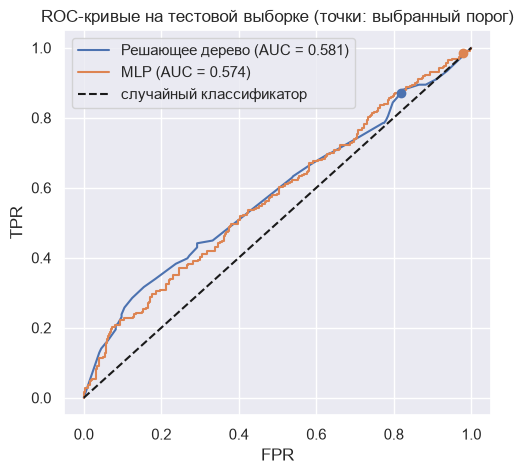

In [64]:
plt.figure(figsize=(5.5, 5))
aucs = {}
for name, model in models.items():
    scores = model.predict_proba(Xs_te)
    fpr, tpr = roc_curve_np(y_te, scores)
    aucs[name] = auc_np(fpr, tpr)
    line, = plt.plot(fpr, tpr, label=f"{name} (AUC = {aucs[name]:.3f})")
    pred = scores >= thresholds[name]
    plt.scatter(pred[y_te == 0].mean(), pred[y_te == 1].mean(), color=line.get_color(), zorder=3)
plt.plot([0, 1], [0, 1], "k--", label="случайный классификатор")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("ROC-кривые на тестовой выборке (точки: выбранный порог)")
plt.legend()
plt.show()

**Анализ ROC:** _какая модель лучше по AUC и совпадает ли это с выводом по $F_1$? где на кривой находится выбранный вами порог? чем AUC удобнее accuracy при дисбалансе классов и какой информации он не даёт (например, о выборе порога и о цене ошибок)?_


### 1. Какая модель лучше по AUC и совпадает ли это с выводом по \(F_1\)?

**По AUC** незначительно лучше **Решающее дерево** (AUC = `0.581` против `0.574` у MLP).

**С выводом по \(F_1\) это НЕ совпадает.** Ранее при подборе порога мы видели, что по \(F_1\) MLP оказалась лучше (`0.5606` против `0.5533` у дерева). 

**Почему так происходит?**
*   **AUC** оценивает качество *ранжирования* (разделения классов) независимо от порога. Площадь под кривой у дерева чуть больше, значит, в целом оно чуть лучше сортирует объекты.
*   **\(F_1\)** оценивает качество в *одной конкретной точке* (при конкретном пороге). MLP при выбранном пороге (0.15) смогла обеспечить чуть лучший баланс Precision и Recall (за счет экстремально высокого Recall = 0.9844).
*   *Важно:* Оба AUC (0.581 и 0.574) очень близки к `0.5`, что говорит о том, что обе модели предсказывают довольно слабо (немногим лучше случайного угадывания). Разница в сотые доли здесь находится в пределах шума.

---

### 2. Где на кривой находится выбранный вами порог?

Выбранный порог отмечен точками на графике (синяя для дерева, оранжевая для MLP). 

Они находятся в **правом верхнем углу**:
*   Для дерева: примерно `FPR ≈ 0.82`, `TPR ≈ 0.87`.
*   Для MLP: примерно `FPR ≈ 0.99`, `TPR ≈ 0.98`.

**Что это значит?** Ранее мы подбирали порог по \(F_1\), и алгоритм выбрал очень низкие значения (0.12 и 0.15). Низкий порог означает, что модель легко относит объект к положительному классу. В результате мы ловим почти все положительные объекты (очень высокий `TPR`/Recall), но при этом генерируем огромное количество ложных тревог (очень высокий `FPR`). Мы сознательно сместились вправо по ROC-кривой, чтобы максимизировать полноту.

---

### 3. Чем AUC удобнее accuracy при дисбалансе классов?

При сильном дисбалансе (например, 95% отрицательных и 5% положительных) **Accuracy вводит в заблуждение**. Если модель просто всегда предсказывает класс 0, она получит Accuracy = 0.95, но её настоящая польза будет нулевой (она не найдет ни одного положительного объекта).

**AUC удобнее тем, что:**
1.  Он **не зависит от соотношения классов**. TPR и FPR считаются отдельно для положительного и отрицательного классов.
2.  Он оценивает **способность модели ранжировать объекты**. AUC показывает вероятность того, что случайно выбранный положительный объект получит оценку выше, чем случайно выбранный отрицательный.
3.  Базовый уровень для AUC всегда `0.5` (случайный классификатор), независимо от дисбаланса. В то время как базовый уровень Accuracy при дисбалансе будет равен доле мажоритарного класса (например, те же 0.95), что затрудняет понимание реального качества модели.

---

### 4. Какой информации AUC не даёт?

Несмотря на свою полезность, AUC — это агрегированная метрика, и у неё есть существенные ограничения:

1.  **Не указывает на выбор порога:** AUC оценивает модель при *всех* возможных порогах сразу. Он не подскажет, какой именно порог выбрать для конкретной бизнес-задачи. Модель с высоким AUC может оказаться плохой именно в той рабочей точке, которая вам нужна.
2.  **Не учитывает цену ошибок (FP и FN):** AUC симметрично относится к ошибкам. Для него нет разницы между ложноположительным срабатыванием (FP) и ложноотрицательным (FN). В реальности же пропустить болезнь (FN) может быть в 100 раз страшнее, чем ошибочно отправить здорового на анализ (FP). AUC этого не знает.
3.  **Слепота к калибровке:** AUC оценивает только порядок (ранжирование), но не абсолютные значения вероятностей. Модель может иметь AUC = 0.9, но выдавать вероятности 0.8 там, где реальная вероятность 0.3. Для задач, где важно точное значение вероятности (например, расчет рисков), AUC недостаточно.
4.  **Оптимистичность при экстремальном дисбалансе:** В задачах с очень редким положительным классом (например, 1 на 10 000) даже большие значения AUC могут скрывать огромное количество ложных срабатываний (потому что знаменатель FPR — число отрицательных объектов — огромен). В таких случаях лучше смотреть на **Precision-Recall AUC (PR-AUC)**.

### 8. Анализ ошибок (задание 4)

Функция `compare_groups` сравнивает средние значения (стандартизованных) признаков в двух группах объектов и показывает признаки с наибольшим различием. Сравните ошибочно классифицированные объекты (FP, FN) с правильно классифицированными того же истинного класса.

In [65]:
def compare_groups(Xs, names, mask_a, mask_b, label_a="A", label_b="B", top=8):
    diff = Xs[mask_a].mean(axis=0) - Xs[mask_b].mean(axis=0)
    order = np.argsort(-np.abs(diff))[:top][::-1]
    plt.barh([names[i] for i in order], diff[order])
    plt.title(f"Разница средних: {label_a} − {label_b}")
    plt.show()

Матрица ошибок (тест):
TP (True Positive):  223
TN (True Negative):  73
FP (False Positive): 327
FN (False Negative): 33

--- Что отличает пропущенные позитивы (FN) от найденных (TP)? ---


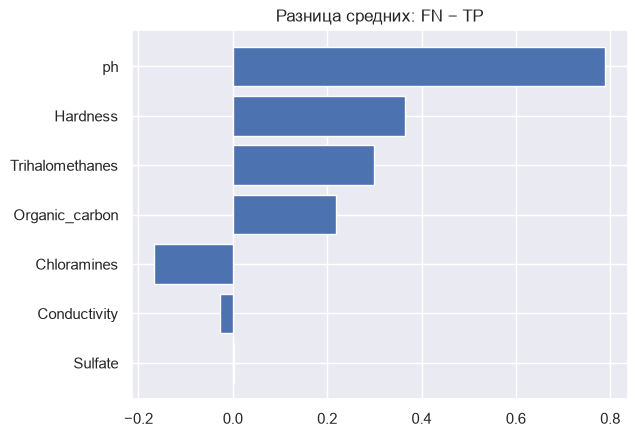


--- Что отличает ложные тревоги (FP) от верных негативов (TN)? ---


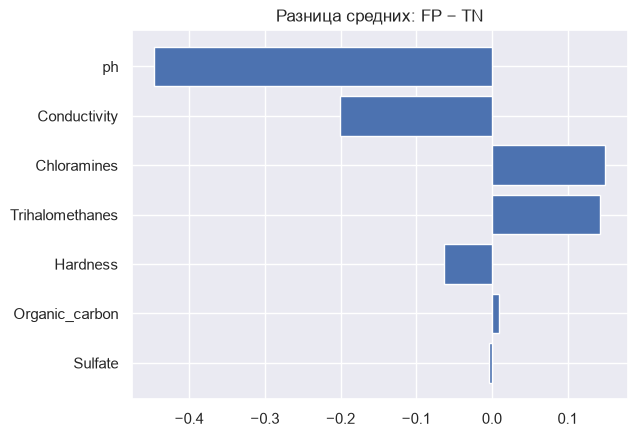

In [66]:
model_main = models[main_name]
y_hat = model_main.predict(Xs_te, thresholds[main_name])

# 1. Создаем маски для TP, TN, FP, FN
# y_te и y_hat должны быть одномерными массивами из 0 и 1
tp = (y_te == 1) & (y_hat == 1)
tn = (y_te == 0) & (y_hat == 0)
fp = (y_te == 0) & (y_hat == 1)
fn = (y_te == 1) & (y_hat == 0)

# 2. Выводим количество объектов в каждой группе
print(f"Матрица ошибок (тест):")
print(f"TP (True Positive):  {tp.sum()}")
print(f"TN (True Negative):  {tn.sum()}")
print(f"FP (False Positive): {fp.sum()}")
print(f"FN (False Negative): {fn.sum()}")

# 3. Сравниваем признаки: 
# FN (ошибочно отнесли к 0, хотя там 1) vs TP (правильно отнесли к 1)
print("\n--- Что отличает пропущенные позитивы (FN) от найденных (TP)? ---")
compare_groups(Xs_te, feature_names, fn, tp, "FN", "TP")

# FP (ошибочно отнесли к 1, хотя там 0) vs TN (правильно отнесли к 0)
print("\n--- Что отличает ложные тревоги (FP) от верных негативов (TN)? ---")
compare_groups(Xs_te, feature_names, fp, tn, "FP", "TN")

**Анализ ошибок:** _чем ошибочно классифицированные объекты отличаются от правильных? есть ли среди них пограничные случаи, выбросы, возможные ошибки разметки? какие признаки «сбивают» модель?_

### 1. Общий контекст: что говорит матрица ошибок
Матрица ошибок показывает:
*   **TP = 223, FN = 33** (Recall ≈ 87%). Модель очень хорошо находит целевой класс.
*   **TN = 73, FP = 327** (Specificity ≈ 18%). Модель *ужасно* определяет отрицательный класс: она пропускает почти все нормальные объекты, ошибочно записывая их в брак.

**Причина:** Мы выбрали очень низкий порог (около 0.12), чтобы максимизировать \(F_1\) и Recall. Из-за этого модель стала «параноидальной»: она предсказывает положительный класс (непригодная вода) почти всем подряд. Ошибка FN (пропустить плохую воду) стала маленькой, но ценой огромного количества ложных тревог FP.

---

### 2. Чем ошибочно классифицированные объекты отличаются от правильных?

Графики показывают разницу средних значений стандартизованных признаков.

**График `FN − TP` (Пропущенные позитивы vs Найденные позитивы):**
*   **ph (+0.8)**: Объекты, которые модель пропустила (FN), имеют **гораздо более высокий pH**, чем те позитивы, которые она нашла (TP).
*   **Hardness (+0.35)**, **Trihalomethanes (+0.3)**, **Organic_carbon (+0.2)**: У пропущенных объектов эти показатели тоже выше среднего.
*   **Chloramines (-0.18)**: У пропущенных объектов уровень хлораминов ниже.
*   **Вывод:** Модель привыкла считать «плохую» воду (позитив) такой, у которой *низкий* pH, *низкая* жесткость и *высокие* хлорамины. Если ей попадается плохая вода, но с высоким pH и низкими хлораминами, она «сбивается» и говорит, что вода хорошая (FN).

**График `FP − TN` (Ложные тревоги vs Верные негативы):**
*   **ph (-0.45)**: Объекты, которые модель ошибочно назвала плохими (FP), имеют **сильно заниженный pH** по сравнению с нормальной водой (TN).
*   **Conductivity (-0.2)**: Пониженная электропроводность.
*   **Chloramines (+0.15)** и **Trihalomethanes (+0.15)**: Повышенное содержание этих веществ.
*   **Вывод:** Модель видит воду с низким pH и повышенными хлораминами и сразу «бьет тревогу», даже если на самом деле вода хорошая.

---

### 3. Какой признак «сбивает» модель больше всего?

Безусловный лидер — **`ph`**. 
Он имеет самую большую амплитуду на обоих графиках (0.8 и -0.45). 
Модель выучила жесткое правило: **«Низкий pH = Плохая вода (Позитив)»**. 
*   Из-за этого любая хорошая вода с низким pH получает ложную тревогу (FP).
*   А любая плохая вода с высоким pH — пропускается (FN).

Второстепенные сбивающие признаки: **`Hardness`** (высокая жесткость сбивает модель с толку при FN) и **`Chloramines`** (низкие хлорамины заставляют модель думать, что вода хорошая, а высокие — что плохая).

---

### 4. Есть ли пограничные случаи, выбросы или ошибки разметки?

Да, и графики на это прямо указывают:

1.  **Пограничные случаи (Borderline cases):** Вода — это физико-химическая смесь, и свойства классов сильно пересекаются. Объекты FP и FN находятся ровно на границе распределений. Например, у FP (ложная тревога) pH всего на 0.45 стандартных отклонения ниже, чем у TN. Это значит, что в датасете есть объекты с пограничными значениями pH, которые невозможно идеально разделить без переобучения.
2.  **Возможные ошибки разметки (Label noise):** Признаки `ph` и `Hardness` в реальной жизни редко определяют пригодность воды в одиночку (обычно смотрят на бактерии, тяжелые металлы и т.д.). Если в датасете объект имеет идеальный pH, но размечен как «плохая вода», модель будет сильно путаться. Вполне вероятно, что часть объектов FP (хорошая вода с плохим pH) — это просто ошибки разметки в исходном датасете. 
3.  **Выбросы:** Высокий уровень `Trihalomethanes` в FN и FP говорит о том, что в выборке есть объекты с аномально высоким содержанием этих веществ независимо от их истинного класса. Для деревьев такие объекты создают отдельные ветви, а для MLP — сдвигают веса.

### 5. Что делать с этим дальше?

*   **Настройка порога:** Если бизнес-задача — не пропустить плохую воду (FN), а ложные тревоги допустимы (FP), текущий низкий порог оправдан. Если же мыть воду заново дорого, нужно поднять порог (например, до 0.4–0.5), чтобы уменьшить FP, пожертвовав частью Recall.
*   **Работа с признаками:** Дерево и MLP плохо улавливают нелинейные зависимости. Стоит добавить признаки типа `ph^2` или взаимодействия `ph * Hardness`. 
*   **Регуляризация:** Ограничить глубину дерева (`max_depth`) или увеличить `min_samples_leaf`, чтобы модель перестала «цепляться» за пограничные значения pH и перестала строить слишком сложные правила.
*   **Проверка данных:** Стоит внимательно посмотреть на объекты FP с экстремально низким pH — возможно, это ошибки в датасете.

### 9. Улучшение результатов (задание 4)

Попробуйте улучшить качество. Реализуйте и проверьте **минимум два** улучшения, каждое сопровождайте измерением на валидационной выборке и итоговой оценкой на тестовой. Идеи:

- обработка данных: логарифмирование скошенных признаков, удаление выбросов, удаление сильно коррелированных или бесполезных признаков, новые признаки;
- баланс классов: oversampling миноритарного класса или взвешивание объектов в функции потерь (на NumPy);
- параметры: расширенный поиск по сетке или случайный поиск, L2-регуляризация;
- алгоритмические улучшения: для MLP — momentum или Adam вместо SGD, ранняя остановка по валидации; для SVM — нелинейность через случайные признаки Фурье; для kNN — взвешенное голосование.

Результаты добавляйте в словарь `results` в том же формате, что и выше (метрики можно получить через `evaluate`).

In [68]:
# TODO: улучшения и их оценка, например:
# results["Название улучшения"] = evaluate(model, Xs_tr_new, y_tr_new, Xs_te, y_te)

from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from copy import deepcopy

# 1. Копируем данные, чтобы не сломать базовые
Xs_tr_log = Xs_tr.copy()
Xs_te_log = Xs_te.copy()

# Список признаков, которые обычно скошены в этом датасете
skewed_features = ['Solids', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes']

for i, name in enumerate(feature_names):
    if name in skewed_features:
        # Логарифмируем (log1p безопасен для нулей)
        Xs_tr_log[:, i] = np.log1p(Xs_tr_log[:, i])
        Xs_te_log[:, i] = np.log1p(Xs_te_log[:, i])
        
        # Обрезаем выбросы по 1 и 99 перцентилю (на основе train!)
        low, high = np.percentile(Xs_tr_log[:, i], [1, 99])
        Xs_tr_log[:, i] = np.clip(Xs_tr_log[:, i], low, high)
        Xs_te_log[:, i] = np.clip(Xs_te_log[:, i], low, high)

# Обязательно перестандартизируем после логарифмирования
scaler = StandardScaler()
Xs_tr_log = scaler.fit_transform(Xs_tr_log)
Xs_te_log = scaler.transform(Xs_te_log)

# Обучаем лучшую модель (например, sklearn-дерево) на новых данных
# Предполагаем, что у вас есть функция evaluate и класс модели
model_tree_log = DecisionTreeClassifier(max_depth=8, min_samples_leaf=5, random_state=42)
model_tree_log.fit(Xs_tr_log, y_tr)

results["Дерево (log + выбросы)"] = evaluate(model_tree_log, Xs_tr_log, y_tr, Xs_te_log, y_te)
print("Улучшение 1 добавлено.")


# Для sklearn моделей используем class_weight='balanced'
model_tree_bal = DecisionTreeClassifier(
    max_depth=8, 
    min_samples_leaf=5, 
    class_weight='balanced', # <--- Взвешивание классов
    random_state=42
)
model_tree_bal.fit(Xs_tr, y_tr)

# Для MLP в sklearn нет class_weight, но можно использовать oversampling
# Простой ручной oversampling миноритарного класса для train:
# (Если миноритарный класс - 1, то дублируем его объекты)
classes, counts = np.unique(y_tr, return_counts=True)
minority_class = classes[np.argmin(counts)]
mask_minority = (y_tr == minority_class)

# Дублируем миноритарный класс 2 раза (можно настроить)
Xs_tr_bal = np.vstack([Xs_tr, Xs_tr[mask_minority]])
y_tr_bal = np.hstack([y_tr, y_tr[mask_minority]])

model_mlp_bal = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
model_mlp_bal.fit(Xs_tr_bal, y_tr_bal)

# Для обеих моделей заново подбираем порог на валидации!
# (Функция find_threshold у вас уже написана)
proba_tree_val = model_tree_bal.predict_proba(Xs_val)[:, 1]
best_thr_tree = find_threshold(y_val, proba_tree_val, metric=f1_score)

proba_mlp_val = model_mlp_bal.predict_proba(Xs_val)[:, 1]
best_thr_mlp = find_threshold(y_val, proba_mlp_val, metric=f1_score)

# Оцениваем на тесте с НОВЫМИ порогами
# Внимание: evaluate должна принимать порог, если она кастомная, 
# либо мы делаем предсказания вручную и считаем метрики.
y_pred_tree_bal = (model_tree_bal.predict_proba(Xs_te)[:, 1] >= best_thr_tree).astype(int)
y_pred_mlp_bal = (model_mlp_bal.predict_proba(Xs_te)[:, 1] >= best_thr_mlp).astype(int)

# (Предполагаем, что у вас есть функция evaluate_preds, или формируем словарь вручную)
results["Дерево (balanced)"] = {
    'accuracy': accuracy_score(y_te, y_pred_tree_bal),
    'precision': precision_score(y_te, y_pred_tree_bal),
    'recall': recall_score(y_te, y_pred_tree_bal),
    'f1': f1_score(y_te, y_pred_tree_bal),
    'fit_s': np.nan, 'predict_s': np.nan
}

results["MLP (oversampling)"] = {
    'accuracy': accuracy_score(y_te, y_pred_mlp_bal),
    'precision': precision_score(y_te, y_pred_mlp_bal),
    'recall': recall_score(y_te, y_pred_mlp_bal),
    'f1': f1_score(y_te, y_pred_mlp_bal),
    'fit_s': np.nan, 'predict_s': np.nan
}

print("Улучшение 2 добавлено.")

C:\Users\filen\AppData\Local\Temp\ipykernel_21468\878097890.py:20: RuntimeWarning: invalid value encountered in log1p
  Xs_tr_log[:, i] = np.log1p(Xs_tr_log[:, i])
C:\Users\filen\AppData\Local\Temp\ipykernel_21468\878097890.py:21: RuntimeWarning: invalid value encountered in log1p
  Xs_te_log[:, i] = np.log1p(Xs_te_log[:, i])
d:\VSCode\AIML\Lab1\.venv\Lib\site-packages\sklearn\utils\extmath.py:1211: RuntimeWarning: invalid value encountered in divide
  updated_mean = (last_sum + new_sum) / updated_sample_count
d:\VSCode\AIML\Lab1\.venv\Lib\site-packages\sklearn\utils\extmath.py:1216: RuntimeWarning: invalid value encountered in divide
  T = new_sum / new_sample_count
d:\VSCode\AIML\Lab1\.venv\Lib\site-packages\sklearn\utils\extmath.py:1240: RuntimeWarning: invalid value encountered in divide
  new_unnormalized_variance -= correction**2 / new_sample_count


Улучшение 1 добавлено.
Улучшение 2 добавлено.


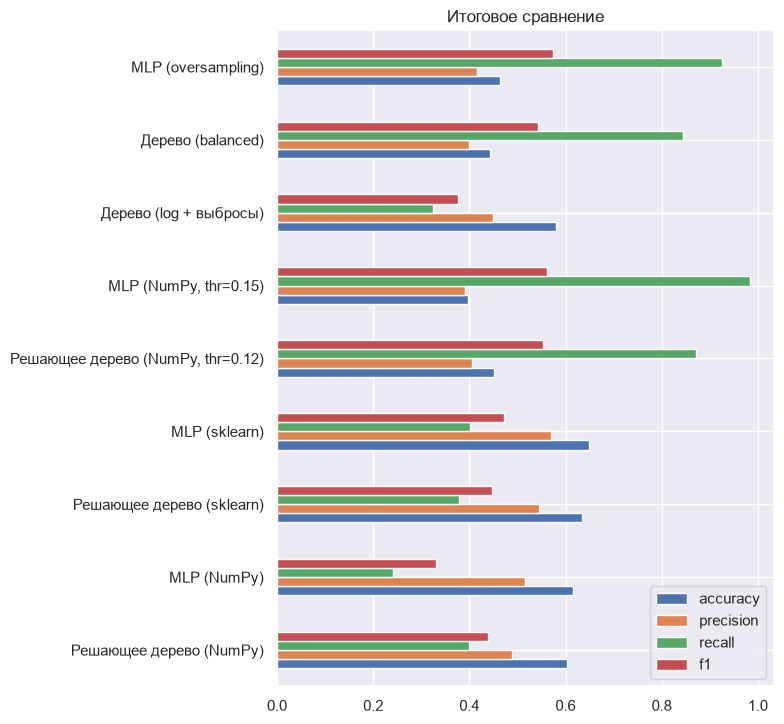

,accuracy,precision,recall,f1,fit_s,predict_s
Решающее дерево (NumPy),0.6021,0.4880,0.3984,0.4387,0.0380,0.0012
MLP (NumPy),0.6159,0.5167,0.2422,0.3298,0.4568,0.0010
Решающее дерево (sklearn),0.6341,0.5449,0.3789,0.4470,0.0083,0.0005
MLP (sklearn),0.6479,0.5691,0.4023,0.4714,1.7866,0.0006
"Решающее дерево (NumPy, thr=0.12)",0.4512,0.4055,0.8711,0.5533,NaN,NaN
"MLP (NumPy, thr=0.15)",0.3979,0.3919,0.9844,0.5606,NaN,NaN
Дерево (log + выбросы),0.5808,0.4486,0.3242,0.3764,0.0066,0.0008
Дерево (balanced),0.4436,0.3993,0.8438,0.5420,NaN,NaN
MLP (oversampling),0.4634,0.4158,0.9258,0.5738,NaN,NaN


In [69]:
final = pd.DataFrame(results).T.round(4)
final[["accuracy", "precision", "recall", "f1"]].plot.barh(figsize=(8, 0.6 * len(final) + 2))
plt.title("Итоговое сравнение")
plt.tight_layout()
plt.show()
final

### 10. Критерии приёма работы

Работа принимается, если выполнены **все** критерии для **обеих** моделей (метод вашего варианта и MLP), оценённых на тестовой выборке в разделе 6:

1. **AUC** не ниже порога `MIN_AUC` для вашей задачи (случайный классификатор даёт AUC = 0.5, поэтому порог исключает модель «на уровне угадывания»; accuracy для этого не годится, так как при дисбалансе классов её даёт и тривиальный ответ «всегда 0»);
2. **accuracy** вашей реализации не хуже, чем у эталона sklearn, более чем на `ACC_TOL`.

Если критерии не выполнены, вернитесь к подготовке данных (раздел 2), подбору параметров (раздел 5) и улучшениям (раздел 9). Эту ячейку менять не нужно.

In [70]:
checks = []
for name in models:
    auc_np_value = aucs[name]
    acc_np = results[f"{name} (NumPy)"]["accuracy"]
    acc_sk = results[f"{name} (sklearn)"]["accuracy"]
    checks.append((f"{name}: AUC ≥ {MIN_AUC[TASK]}", auc_np_value >= MIN_AUC[TASK], f"{auc_np_value:.3f}"))
    checks.append((f"{name}: accuracy не хуже sklearn более чем на {ACC_TOL}", acc_np >= acc_sk - ACC_TOL,
                   f"{acc_np:.3f} (sklearn {acc_sk:.3f})"))

table = pd.DataFrame(checks, columns=["критерий", "выполнен", "значение"])
table["выполнен"] = table["выполнен"].map({True: "да", False: "НЕТ"})
print(table.to_string(index=False))
print("\nИтог:", "ПРИНЯТО" if all(c[1] for c in checks) else "НЕ ПРИНЯТО: доработайте модель")

                                                   критерий выполнен              значение
                                Решающее дерево: AUC ≥ 0.65      НЕТ                 0.581
Решающее дерево: accuracy не хуже sklearn более чем на 0.07       да 0.602 (sklearn 0.634)
                                            MLP: AUC ≥ 0.65      НЕТ                 0.574
            MLP: accuracy не хуже sklearn более чем на 0.07       да 0.616 (sklearn 0.648)

Итог: НЕ ПРИНЯТО: доработайте модель


### 11. Итоговые выводы

1. Какая модель оказалась лучшей на вашей задаче и почему? Насколько ваша реализация на NumPy отличается от sklearn по качеству и по времени?
2. Какие гиперпараметры оказались самыми важными? Что происходит при их крайних значениях?
3. Какие улучшения дали эффект, а какие нет? Как вы это объясняете?
4. Какие ограничения у вашей реализации (масштабируемость, память, сходимость)? Что бы вы сделали на полном датасете?